# Deep Learning 6

## Arquiteturas: das convoluções à U-Net e aos embeddings

Link Colab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ftl-brazil-2026/ebook/blob/main/deep-learning/dl6_arquiteturas.ipynb)

Até aqui usamos redes simples: MLPs e uma CNN pequena. Hoje vamos conhecer as **arquiteturas** que marcaram a
evolução do Deep Learning, entender **por que** cada uma surgiu e usar modelos de verdade, pré-treinados, baixados
do Hugging Face.

**Roteiro**

1. **Convoluções**: a operação que mudou a visão computacional
2. **Empilhando convoluções**: das camadas convolucionais às camadas densas, o problema da profundidade e a **ResNet**
   (*skip connections*)
3. **Hugging Face**: o que é, como se conectar e como carregar uma **ResNet-50 pré-treinada**
4. **U-Net**: escrevendo a arquitetura de segmentação do zero e usando-a para mapear uso do solo em imagens aéreas,
   com e sem um encoder pré-treinado do Hugging Face
5. **Embeddings**: como as redes guardam o que aprenderam em vetores de muitas dimensões

O mecanismo de **atenção** (Transformers, ViT) e o aprendizado auto-supervisionado ficam para a aula 7
(`dl7_atencao.ipynb`).

Para cada arquitetura há uma **ficha** 🗂️ com o ano, se é antiga ou recente, o tipo de treino, por que é
importante, pontos fortes e limitações.



In [ ]:
# no Google Colab, o PyTorch já vem instalado; o timm pode não vir
import sys
if "google.colab" in sys.modules:
    !pip install -q timm

In [2]:
import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")     # saída mais limpa ao baixar do Hugging Face
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from skimage import data, io
from PIL import Image

# cores e estilo dos gráficos (as mesmas das aulas de Machine Learning)
AZUL, LARANJA, VERDE, CINZA, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 110,
})

torch.manual_seed(42)
np.random.seed(42)

# redes grandes (ResNet-50, U-Net) ganham com GPU, inclusive a do Mac (MPS); redes pequenas rodam melhor na CPU
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DEVICE_PEQUENO = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | redes grandes: {DEVICE} | redes pequenas: {DEVICE_PEQUENO}")

PyTorch 2.14.1 | redes grandes: mps | redes pequenas: cpu


### Uma linha do tempo

Cada ponto é uma arquitetura que mudou o rumo da área. Repare em três "eras": as **CNNs** (convoluções), as
**redes muito profundas** com conexões residuais, e os **Transformers**, que hoje são treinados cada vez mais de
forma **auto-supervisionada** (sem rótulos).

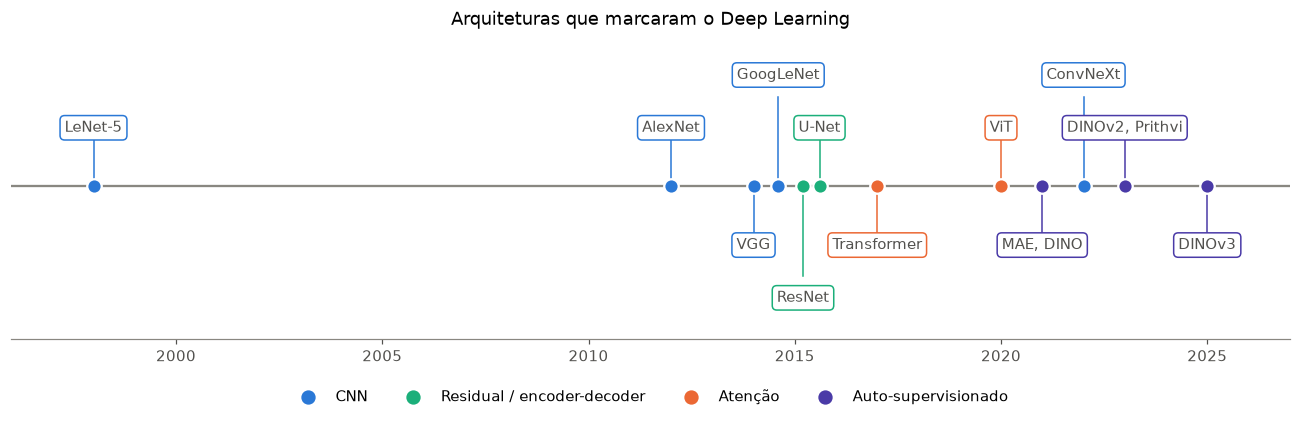

In [3]:
marcos = [  # (ano, nome, família, deslocamento vertical do rótulo)
    (1998, "LeNet-5", "CNN", 1), (2012, "AlexNet", "CNN", 1), (2014, "VGG", "CNN", -1),
    (2014.6, "GoogLeNet", "CNN", 1.9), (2015.2, "ResNet", "Residual / encoder-decoder", -1.9),
    (2015.6, "U-Net", "Residual / encoder-decoder", 1), (2017, "Transformer", "Atenção", -1),
    (2020, "ViT", "Atenção", 1), (2021, "MAE, DINO", "Auto-supervisionado", -1),
    (2022, "ConvNeXt", "CNN", 1.9), (2023, "DINOv2, Prithvi", "Auto-supervisionado", 1),
    (2025, "DINOv3", "Auto-supervisionado", -1),
]
cores_familia = {"CNN": AZUL, "Residual / encoder-decoder": VERDE, "Atenção": LARANJA, "Auto-supervisionado": "#4a3aa7"}

fig, ax = plt.subplots(figsize=(15, 3.6))
ax.axhline(0, color=CINZA, lw=1.5, zorder=1)
for ano, nome, familia, dy in marcos:
    cor = cores_familia[familia]
    ax.plot([ano, ano], [0, dy * 0.8], color=cor, lw=1, zorder=1)
    ax.scatter(ano, 0, s=90, color=cor, zorder=3, edgecolor="white", lw=1.5)
    ax.text(ano, dy, nome, ha="center", va="center", color=TINTA, fontsize=10,
            bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": cor})
for familia, cor in cores_familia.items():
    ax.scatter([], [], s=70, color=cor, label=familia)
ax.set(xlim=(1996, 2027), ylim=(-2.6, 2.6), yticks=[], title="Arquiteturas que marcaram o Deep Learning")
ax.spines["left"].set_visible(False)
ax.grid(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=4)
plt.show()

# Parte 1 — Convoluções

## 1.1 Por que não usar um MLP em imagens?

Nas aulas anteriores, "achatamos" a imagem do MNIST em um vetor de 784 números.

Um dos maiores problemas é perder toda a informação espacial da imagem, perdemos os objetos e seus vizinhos, jogamos fora a primeira lei de Tobler. 
Além disso não é eficiente vetorizar imagens grandes, teríamos redes extremamente grandes que são fáceis de acontecerem um overfitting. 

In [4]:
for nome, (h, w, c) in {"MNIST": (28, 28, 1), "foto 224 × 224 RGB": (224, 224, 3), "imagem Sentinel-2 512 × 512, 13 bandas": (512, 512, 13)}.items():
    entradas = h * w * c
    print(f"{nome:<40} {entradas:>10,} entradas → 1ª camada densa com 128 neurônios = {entradas * 128:>14,} pesos")

MNIST                                           784 entradas → 1ª camada densa com 128 neurônios =        100,352 pesos
foto 224 × 224 RGB                          150,528 entradas → 1ª camada densa com 128 neurônios =     19,267,584 pesos
imagem Sentinel-2 512 × 512, 13 bandas    3,407,872 entradas → 1ª camada densa com 128 neurônios =    436,207,616 pesos


Três problemas de usar camadas densas direto nos pixels:

1. **Parâmetros demais**: centenas de milhões de pesos já na primeira camada.
2. **Sem noção de vizinhança**: para a camada densa, o pixel (0, 0) e o pixel (0, 1) são tão "distantes" quanto
   o (0, 0) e o (223, 223).
3. **Sem invariância à translação**: um gato no canto esquerdo e um gato no canto direito ativam pesos
   completamente diferentes; a rede teria que aprender "gato" separadamente em cada posição.

A **convolução** aborda essas falhas de utilizar MLP para imagens, através do kernel ou também conhecido como filtro (exemplo 3 × 3), o mesmo filtro desliza pela imagem, e possui apenas 9 pesos referente aquele filtro. Isso cria um peso compartilhado para a imagem inteira, o que beneficia a generalização das redes. 


## 1.2 A convolução

Em cada posição, multiplicamos o filtro (*kernel*) pelos pixels embaixo dele, elemento a elemento, e somamos.
O resultado vira um pixel da saída, o **mapa de características** (*feature map*).

In [5]:
def convolucao_manual(imagem, kernel):
    """Convolução 2D (sem padding, passo 1)."""
    H, W = imagem.shape
    k = kernel.shape[0]
    saida = torch.zeros(H - k + 1, W - k + 1)
    for i in range(H - k + 1):
        for j in range(W - k + 1):
            janela = imagem[i:i + k, j:j + k]
            saida[i, j] = (janela * kernel).sum()      # multiplica elemento a elemento e soma
    return saida

imagem = torch.tensor([[0, 0, 0, 0, 0, 0],
                       [0, 9, 9, 9, 9, 0],
                       [0, 9, 0, 0, 9, 0],
                       [0, 9, 0, 0, 9, 0],
                       [0, 9, 9, 9, 9, 0],
                       [0, 0, 0, 0, 0, 0]], dtype=torch.float32)

kernel = torch.tensor([[-1, 0, 1],
                       [-1, 0, 1],
                       [-1, 0, 1]], dtype=torch.float32)    # detecta bordas verticais

saida = convolucao_manual(imagem, kernel)

# escrita em pytorch
saida_torch = F.conv2d(imagem[None, None], kernel[None, None])[0, 0]   # (lote, canal, H, W)
print(f"entrada {tuple(imagem.shape)} * kernel {tuple(kernel.shape)} - saída {tuple(saida.shape)}")
print(f"igual ao F.conv2d do PyTorch? {torch.equal(saida, saida_torch)}")

entrada (6, 6) * kernel (3, 3) - saída (4, 4)
igual ao F.conv2d do PyTorch? True


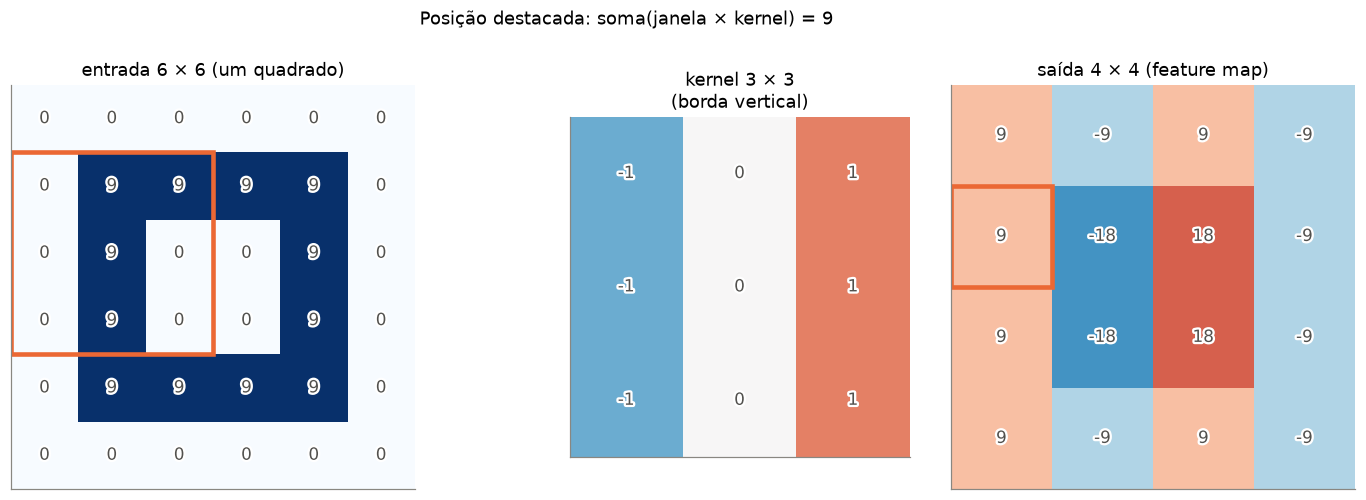

In [6]:
def desenha_matriz(ax, m, titulo, destaque=None, cmap="Blues", vmin=None, vmax=None):
    ax.imshow(m, cmap=cmap, vmin=vmin, vmax=vmax)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m[i, j]:g}", ha="center", va="center", fontsize=11, color=TINTA,
                    path_effects=[pe.withStroke(linewidth=3, foreground="white")])
    if destaque:
        (i, j, k) = destaque
        ax.add_patch(Rectangle((j - 0.5, i - 0.5), k, k, fill=False, edgecolor=LARANJA, lw=3))
    ax.set(title=titulo, xticks=[], yticks=[])
    ax.grid(False)

i, j = 1, 0   # posição destacada
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), width_ratios=[6, 3, 4])
desenha_matriz(axes[0], imagem.numpy(), "entrada 6 × 6 (um quadrado)", destaque=(i, j, 3))
desenha_matriz(axes[1], kernel.numpy(), "kernel 3 × 3\n(borda vertical)", cmap="RdBu_r", vmin=-2, vmax=2)
desenha_matriz(axes[2], saida.numpy(), "saída 4 × 4 (feature map)", destaque=(i, j, 1), cmap="RdBu_r", vmin=-30, vmax=30)
janela = imagem[i:i + 3, j:j + 3]
plt.suptitle(f"Posição destacada: soma(janela × kernel) = {(janela * kernel).sum():g}", y=1.0)
plt.tight_layout()
plt.show()

O kernel de borda vertical responde **positivo** na borda esquerda do quadrado (escuro → claro) e **negativo** na
borda direita (claro → escuro). No interior, onde a imagem é constante, a resposta é zero.

> Detalhe: o que o PyTorch chama de convolução é, matematicamente, uma **correlação cruzada** (o kernel não é
> espelhado). Para redes neurais tanto faz: os pesos do kernel são aprendidos.

## 1.3 Filtros clássicos em uma imagem real

Antes do Deep Learning, os filtros eram desenhados à mão por especialistas.  Já estudamos eles em detalhe na aula de [Imagem Processing](fundamentals_gis_rs/week3/image_processing2.ipynb)

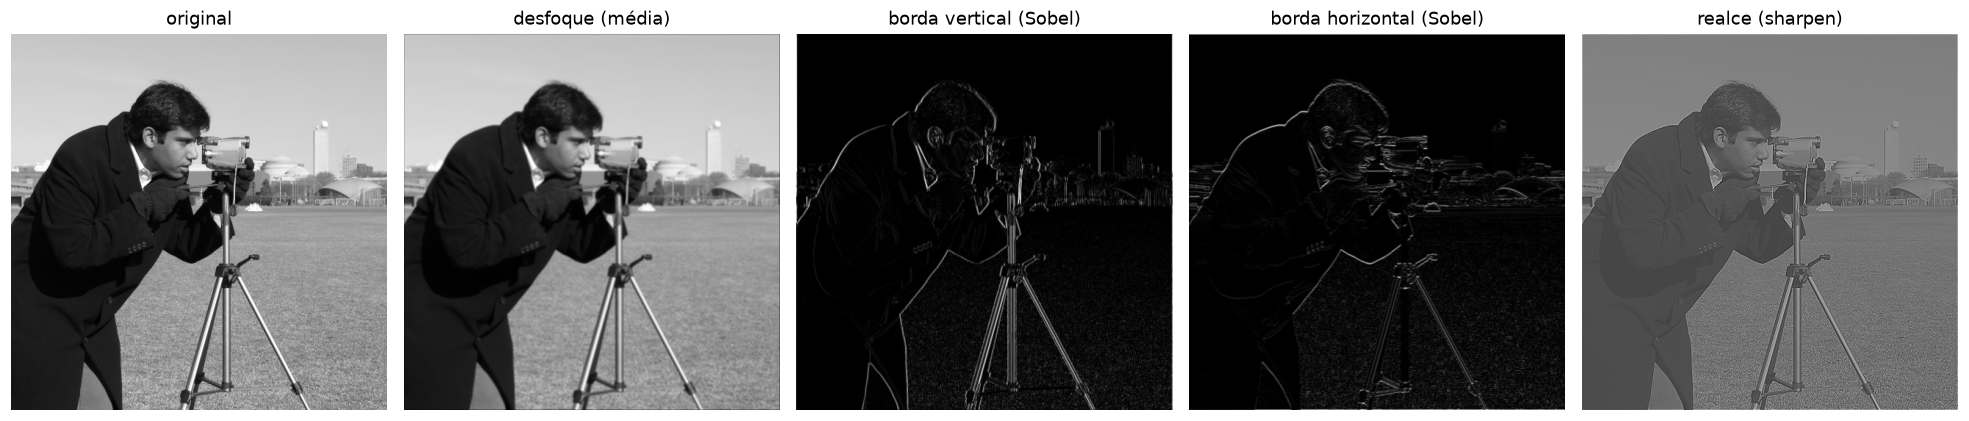

In [7]:
foto = torch.tensor(data.camera(), dtype=torch.float32)[None, None] / 255     # (1, 1, 512, 512)
filtros = {
    "original": [[0, 0, 0], [0, 1, 0], [0, 0, 0]],
    "desfoque (média)": [[1 / 9] * 3] * 3,
    "borda vertical (Sobel)": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
    "borda horizontal (Sobel)": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
    "realce (sharpen)": [[0, -1, 0], [-1, 5, -1], [0, -1, 0]],
}
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (nome, k) in zip(axes, filtros.items()):
    resposta = F.conv2d(foto, torch.tensor(k, dtype=torch.float32)[None, None], padding=1)[0, 0]
    ax.imshow(resposta.abs() if "borda" in nome else resposta, cmap="gray")
    ax.set_title(nome)
    ax.axis("off")
plt.tight_layout()
plt.show()

A grande ideia das **CNNs** (*Convolutional Neural Networks*): em vez de desenhar os filtros à mão, deixamos os
**valores dos kernels serem pesos treináveis**. A rede descobre sozinha, pela descida do gradiente, quais filtros
são úteis para a tarefa.

## 1.4 Anatomia de uma camada `nn.Conv2d`

| Parâmetro | O que controla |
|---|---|
| `in_channels` | canais da entrada (1 para cinza, 3 para RGB, 13 para Sentinel-2) |
| `out_channels` | quantos filtros a camada aprende = quantos *feature maps* ela produz |
| `kernel_size` | tamanho do filtro (3 × 3 é o mais comum) |
| `stride` | o passo com que o filtro desliza (2 = a saída fica com metade do tamanho) |
| `padding` | bordas de zeros adicionadas (com `padding=1` e kernel 3, a saída tem o mesmo tamanho) |

Tamanho da saída: $\text{saída} = \left\lfloor \frac{\text{entrada} + 2 \cdot \text{padding} - \text{kernel}}{\text{stride}} \right\rfloor + 1$

Número de pesos: $\text{out\_channels} \times (\text{in\_channels} \times k \times k) + \text{out\_channels}$ (vieses).
Repare que **não depende do tamanho da imagem**.

In [8]:
x = torch.randn(1, 3, 224, 224)      # uma imagem RGB 224 × 224
configs = [
    dict(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=0),
    dict(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1),
    dict(in_channels=3, out_channels=16, kernel_size=3, stride=2, padding=1),
    dict(in_channels=3, out_channels=64, kernel_size=7, stride=2, padding=3),   # a 1ª camada da ResNet-50
]
linhas = []
for cfg in configs:
    conv = nn.Conv2d(**cfg)
    linhas.append({**cfg, "pesos do kernel": tuple(conv.weight.shape), "nº de parâmetros": sum(p.numel() for p in conv.parameters()),
                   "saída": tuple(conv(x).shape)})
pd.DataFrame(linhas)

,in_channels,out_channels,kernel_size,stride,padding,pesos do kernel,nº de parâmetros,saída
0,3,16,3,1,0,"(16, 3, 3, 3)",448,"(1, 16, 222, 222)"
1,3,16,3,1,1,"(16, 3, 3, 3)",448,"(1, 16, 224, 224)"
2,3,16,3,2,1,"(16, 3, 3, 3)",448,"(1, 16, 112, 112)"
3,3,64,7,2,3,"(64, 3, 7, 7)",9472,"(1, 64, 112, 112)"


Com 3 canais de entrada, cada filtro tem formato `(3, k, k)`: ele olha os três canais **ao mesmo tempo** e soma
tudo em um único mapa. A primeira camada da ResNet-50 tem 64 filtros 7 × 7 × 3 = **9.472 parâmetros**, contra os
~150 milhões de uma camada densa equivalente.

## 1.5 *Pooling*: resumir e reduzir

O ***max pooling*** divide o mapa em janelas (normalmente 2 × 2) e guarda só o maior valor de cada uma. Reduz o
tamanho pela metade, não tem pesos, e deixa a rede tolerante a pequenos deslocamentos.

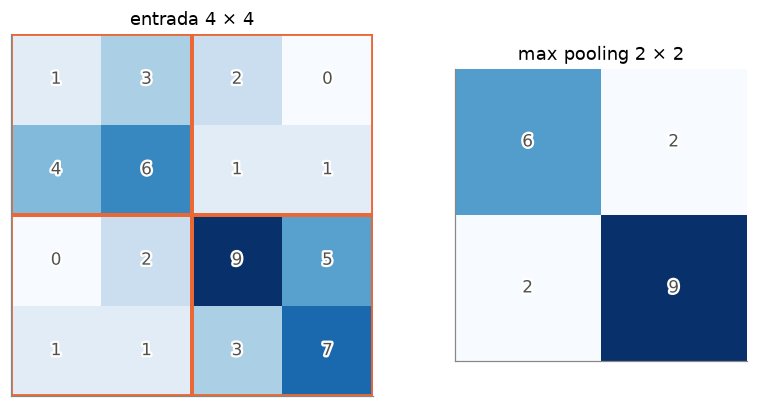

In [9]:
m = torch.tensor([[1, 3, 2, 0],
                  [4, 6, 1, 1],
                  [0, 2, 9, 5],
                  [1, 1, 3, 7]], dtype=torch.float32)
pool = F.max_pool2d(m[None, None], kernel_size=2)[0, 0]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.8), width_ratios=[4, 2])
desenha_matriz(axes[0], m.numpy(), "entrada 4 × 4")
for (i, j) in [(0, 0), (0, 2), (2, 0), (2, 2)]:
    axes[0].add_patch(Rectangle((j - 0.5, i - 0.5), 2, 2, fill=False, edgecolor=LARANJA, lw=2.5))
desenha_matriz(axes[1], pool.numpy(), "max pooling 2 × 2")
plt.tight_layout()
plt.show()

> ### 🗂️ Ficha: Convolução e CNN (LeNet-5)
>
> | | |
> |---|---|
> | **Ano** | 1989 (primeira CNN treinada com backprop, LeCun) e 1998 (LeNet-5) |
> | **Antiga ou nova?** | **Antiga**: a ideia tem mais de 35 anos, mas a convolução continua em praticamente todo modelo de visão |
> | **Tipo de treino** | **supervisionado**: imagens com rótulos (no caso da LeNet-5, dígitos de cheques bancários) |
> | **Por que é importante** | provou que filtros **aprendidos** superam filtros desenhados à mão; introduziu o padrão conv → pooling → camadas densas |
> | **Pontos fortes** | poucos parâmetros (**compartilhamento de pesos**), noção de vizinhança, invariância a pequenos deslocamentos; funciona bem com poucos dados |
> | **Limitações** | cada filtro só enxerga uma região pequena (**campo receptivo local**); relações entre partes distantes da imagem exigem muitas camadas |
> | **Ainda é usada?** | a operação, sim, em todo lugar; a LeNet-5 em si é um exemplo didático |

# Parte 2 — Empilhando convoluções: das camadas convolucionais às densas

## 2.1 A anatomia de uma CNN

Uma CNN clássica tem duas metades:

1. **Extrator de características** (*backbone*): blocos de **conv - ReLU - pooling** empilhados. A cada bloco o mapa
   fica **menor** (pooling) e **mais profundo** (mais canais).
2. **Classificador** (*head*): o último mapa é achatado (`Flatten`) e passa por **camadas densas**, como no MLP das
   aulas anteriores.

Vamos montar a LeNet-5 e acompanhar o formato do tensor camada por camada:

In [10]:
lenet = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.ReLU(), nn.MaxPool2d(2),   # bloco 1
    nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(), nn.MaxPool2d(2),             # bloco 2
    nn.Flatten(),                                                            # mapa  vetor #FC
    nn.Linear(16 * 5 * 5, 120), nn.ReLU(),                                   # camadas densas FULLY CONNECTED LAYER
    nn.Linear(120, 84), nn.ReLU(),
    nn.Linear(84, 10),
)

x = torch.zeros(1, 1, 28, 28)
linhas = [{"camada": "entrada", "formato da saída": tuple(x.shape), "parâmetros": 0}]
for camada in lenet:
    x = camada(x)
    linhas.append({"camada": camada.__class__.__name__, "formato da saída": tuple(x.shape),
                   "parâmetros": sum(p.numel() for p in camada.parameters())})
tabela = pd.DataFrame(linhas)
tabela

,camada,formato da saída,parâmetros
0,entrada,"(1, 1, 28, 28)",0
1,Conv2d,"(1, 6, 28, 28)",156
2,ReLU,"(1, 6, 28, 28)",0
3,MaxPool2d,"(1, 6, 14, 14)",0
4,Conv2d,"(1, 16, 10, 10)",2416
5,ReLU,"(1, 16, 10, 10)",0
6,MaxPool2d,"(1, 16, 5, 5)",0
7,Flatten,"(1, 400)",0
8,Linear,"(1, 120)",48120
9,ReLU,"(1, 120)",0


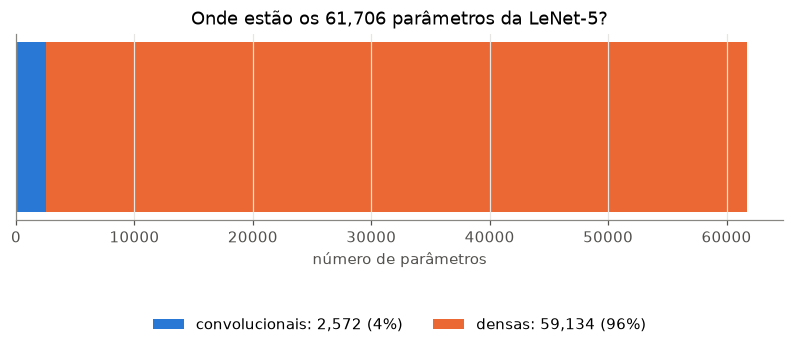

In [11]:
conv_params = sum(p.numel() for c in lenet if isinstance(c, nn.Conv2d) for p in c.parameters())
dense_params = sum(p.numel() for c in lenet if isinstance(c, nn.Linear) for p in c.parameters())
total = conv_params + dense_params

fig, ax = plt.subplots(figsize=(9, 2.2))
ax.barh([0], [conv_params], color=AZUL, height=0.5, label=f"convolucionais: {conv_params:,} ({conv_params / total:.0%})")
ax.barh([0], [dense_params], left=[conv_params], color=LARANJA, height=0.5, label=f"densas: {dense_params:,} ({dense_params / total:.0%})")
ax.set(yticks=[], xlabel="número de parâmetros", title=f"Onde estão os {total:,} parâmetros da LeNet-5?")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.45), ncols=2)
ax.grid(axis="y", visible=False)
plt.show()

**Uma informação interessante:** as camadas convolucionais fazem quase todo o "trabalho de enxergar", mas têm só
~4% dos parâmetros. A maior parte do modelo está nas camadas **densas** do final, logo depois do `Flatten`. Em redes
maiores isso piora: na VGG-16, ~90% dos 138 milhões de parâmetros estão nas três camadas densas. Veremos adiante como
as arquiteturas modernas resolveram isso.

## 2.2 O que cada camada enxerga

Treinamos a LeNet-5 por uma época no MNIST (cerca de 10 segundos) e olhamos para dentro dela.

In [12]:
mnist = datasets.MNIST("data", train=True, download=True, transform=transforms.ToTensor())
X_mnist = mnist.data.float().div(255).unsqueeze(1)
y_mnist = mnist.targets

torch.manual_seed(0)
lenet = lenet.to(DEVICE_PEQUENO)
otimizador = torch.optim.Adam(lenet.parameters(), lr=1e-3)
inicio = time.time()
for lote in torch.randperm(50000).split(128):
    otimizador.zero_grad()
    perda = F.cross_entropy(lenet(X_mnist[lote].to(DEVICE_PEQUENO)), y_mnist[lote].to(DEVICE_PEQUENO))
    perda.backward()
    otimizador.step()
with torch.no_grad():
    acc = (lenet(X_mnist[50000:].to(DEVICE_PEQUENO)).argmax(1).cpu() == y_mnist[50000:]).float().mean()
print(f"LeNet-5, 1 época: acurácia de validação = {acc:.2%} ({time.time() - inicio:.0f} s)")

LeNet-5, 1 época: acurácia de validação = 96.61% (4 s)


In [13]:
digito = X_mnist[50000:50001].to(DEVICE_PEQUENO)    # um dígito da validação
lenet[:3](digito).shape

torch.Size([1, 6, 14, 14])

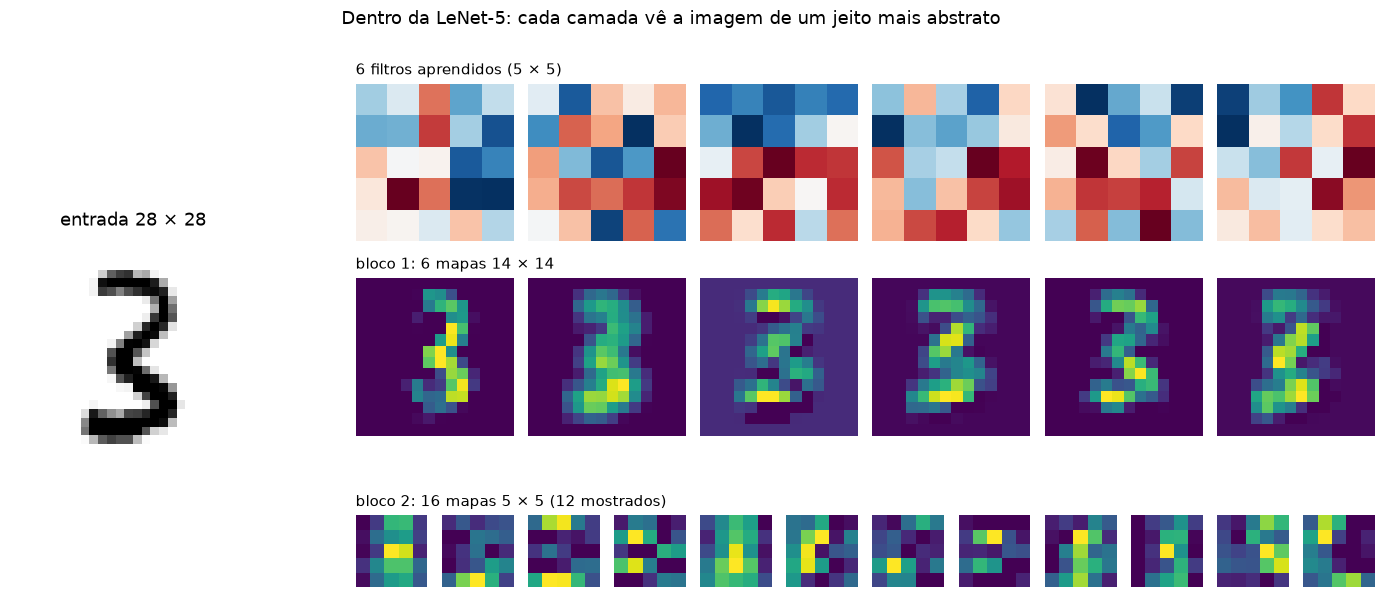

In [14]:
digito = X_mnist[50000:50001].to(DEVICE_PEQUENO)
with torch.no_grad():
    mapas1 = lenet[:3](digito)[0].cpu()      # depois do bloco 1: (6, 14, 14)
    mapas2 = lenet[:6](digito)[0].cpu()      # depois do bloco 2: (16, 5, 5)
filtros1 = lenet[0].weight.detach().cpu()[:, 0]

fig = plt.figure(figsize=(16, 6.5))
grade = fig.add_gridspec(3, 16, height_ratios=[1, 1, 1])
ax = fig.add_subplot(grade[:, :3]); ax.imshow(digito[0, 0].cpu(), cmap="gray_r"); ax.set_title("entrada 28 × 28"); ax.axis("off")
for k in range(6):
    ax = fig.add_subplot(grade[0, 4 + 2 * k:6 + 2 * k]); ax.imshow(filtros1[k], cmap="RdBu_r"); ax.axis("off")
    if k == 0: ax.set_title("6 filtros aprendidos (5 × 5)", loc="left", fontsize=10)
    ax = fig.add_subplot(grade[1, 4 + 2 * k:6 + 2 * k]); ax.imshow(mapas1[k], cmap="viridis"); ax.axis("off")
    if k == 0: ax.set_title("bloco 1: 6 mapas 14 × 14", loc="left", fontsize=10)
for k in range(12):
    ax = fig.add_subplot(grade[2, 4 + k]); ax.imshow(mapas2[k], cmap="viridis"); ax.axis("off")
    if k == 0: ax.set_title("bloco 2: 16 mapas 5 × 5 (12 mostrados)", loc="left", fontsize=10)
plt.suptitle("Dentro da LeNet-5: cada camada vê a imagem de um jeito mais abstrato")
plt.show()

No **bloco 1**, cada mapa ainda se parece com o dígito: são versões filtradas (bordas em direções diferentes). No
**bloco 2**, os mapas são pequenos e abstratos: cada pixel resume uma **região grande** da imagem original.

### Receptive Field
### O campo receptivo cresce com a profundidade

O **campo receptivo** é o pedaço da imagem original que influencia um pixel de um mapa. Cada convolução e cada pooling
aumentam esse pedaço. É por isso que redes **profundas** conseguem reconhecer objetos inteiros com filtros pequenos:
as primeiras camadas veem bordas, as do meio veem partes (olhos, rodas, telhados) e as últimas veem objetos.

In [15]:
def campo_receptivo(camadas):
    """camadas: lista de (nome, kernel, stride). Devolve o campo receptivo depois de cada uma."""
    r, salto, linhas = 1, 1, []
    for nome, k, s in camadas:
        r = r + (k - 1) * salto
        salto *= s
        linhas.append({"camada": nome, "campo receptivo (pixels)": f"{r} × {r}"})
    return pd.DataFrame(linhas)

print("LeNet-5:")
display(campo_receptivo([("conv 5×5", 5, 1), ("pool 2×2", 2, 2), ("conv 5×5", 5, 1), ("pool 2×2", 2, 2)]))
print("10 convoluções 3×3 seguidas, com um pool 2×2 a cada 2:")
display(campo_receptivo([(f"conv 3×3 #{i + 1}" if i % 3 < 2 else "pool 2×2", 3 if i % 3 < 2 else 2, 1 if i % 3 < 2 else 2)
                         for i in range(15)]).tail(4))

LeNet-5:


,camada,campo receptivo (pixels)
0,conv 5×5,5 × 5
1,pool 2×2,6 × 6
2,conv 5×5,14 × 14
3,pool 2×2,16 × 16


10 convoluções 3×3 seguidas, com um pool 2×2 a cada 2:


,camada,campo receptivo (pixels)
11,pool 2×2,76 × 76
12,conv 3×3 #13,108 × 108
13,conv 3×3 #14,140 × 140
14,pool 2×2,156 × 156


## 2.3 A evolução: mais fundo, mais dados, GPUs

Por 14 anos, CNNs como a LeNet ficaram restritas a problemas pequenos. Em 2012 três coisas se juntaram: um dataset
enorme com rótulos (**ImageNet**, 1,2 milhão de imagens, 1.000 classes), **GPUs** e algumas ideias simples (ReLU,
*dropout*). O resultado foi a AlexNet, e a partir dela a regra parecia ser: **quanto mais fundo, melhor**.

> ### 🗂️ Ficha: AlexNet
>
> | | |
> |---|---|
> | **Ano** | 2012 (Krizhevsky, Sutskever e Hinton) |
> | **Antiga ou nova?** | **Antiga**, mas é o marco zero do Deep Learning moderno |
> | **Tipo de treino** | **supervisionado** no ImageNet (1,2 milhão de imagens rotuladas, 1.000 classes), em 2 GPUs |
> | **Por que é importante** | venceu o desafio ImageNet 2012 com uma margem enorme (erro top-5 de ~15%, contra ~26% do 2º lugar) e convenceu a comunidade de que redes profundas funcionam |
> | **Pontos fortes** | popularizou a **ReLU** (treino muito mais rápido que com sigmoide), o **dropout** e o treino em GPU |
> | **Limitações** | 8 camadas e ~60 milhões de parâmetros, a maioria nas camadas densas; filtros grandes (11 × 11) e muitos detalhes ad hoc |
> | **Ainda é usada?** | não em produção; tem valor histórico |

> ### 🗂️ Ficha: VGG
>
> | | |
> |---|---|
> | **Ano** | 2014 (Simonyan e Zisserman, Oxford) |
> | **Antiga ou nova?** | **Antiga** |
> | **Tipo de treino** | **supervisionado** no ImageNet |
> | **Por que é importante** | mostrou que **profundidade** importa (16 a 19 camadas) e que basta empilhar convoluções **3 × 3**: duas 3 × 3 têm o campo receptivo de uma 5 × 5 com menos parâmetros |
> | **Pontos fortes** | arquitetura simples e regular, fácil de entender e de implementar; muito usada como extratora de características |
> | **Limitações** | **pesada**: ~138 milhões de parâmetros (VGG-16), ~90% nas camadas densas; lenta; não dá para ir muito mais fundo sem o treino degradar |
> | **Ainda é usada?** | pouco; aparece em *perceptual loss* e em exemplos didáticos |

## 2.4 O problema da profundidade

Se profundidade ajuda, por que não 100 camadas? Os autores da ResNet perceberam algo estranho: a partir de certo
ponto, redes **mais profundas** ficavam **piores**, inclusive no **treino**. Não era *overfitting* (que piora só a
validação): a rede simplesmente não conseguia ser otimizada. O sinal (e o gradiente) precisa atravessar dezenas de
camadas, e se degrada no caminho.

### A ideia da ResNet: a conexão residual (*skip connection*)

Em vez de pedir para um bloco de camadas aprender a transformação completa $H(x)$, a ResNet pede para ele aprender
só a **diferença** (o *resíduo*) $F(x) = H(x) - x$, e soma a entrada de volta:

$$\text{saída} = \text{ReLU}\big(F(x) + x\big)$$

```
        x ──────────────────────────┐   (atalho: a entrada passa direto)
        │                           │
        ▼                           │
   conv 3×3 → BatchNorm → ReLU      │
        ▼                           │
   conv 3×3 → BatchNorm             │
        ▼                           │
        + ◄─────────────────────────┘
        ▼
      ReLU
```

Duas consequências:

1. Se o melhor que o bloco pode fazer é "não atrapalhar", basta aprender $F(x) = 0$, o que é fácil. Então adicionar
   blocos **nunca deveria piorar** a rede.
2. Na retropropagação, a soma cria uma **estrada direta** para o gradiente: ele chega às primeiras camadas sem
   precisar atravessar todas as convoluções.

Em código, a diferença entre um bloco comum e um bloco residual é **um `+ x`**:

In [16]:
class Bloco(nn.Module):
    """Bloco com duas convoluções 3×3. residual=True adiciona a skip connection."""

    def __init__(self, canais, residual=True):
        super().__init__()
        self.residual = residual
        self.conv1 = nn.Conv2d(canais, canais, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(canais)
        self.conv2 = nn.Conv2d(canais, canais, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(canais)

    def forward(self, x):
        y = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual:
            y = y + x                 #  skip connection: soma a entrada de volta
        return F.relu(y)


class RedeProfunda(nn.Module):
    def __init__(self, n_blocos, residual, canais=16):
        super().__init__()
        self.entrada = nn.Sequential(nn.Conv2d(1, canais, 3, padding=1, bias=False), nn.BatchNorm2d(canais), nn.ReLU())
        self.blocos = nn.Sequential(*[Bloco(canais, residual) for _ in range(n_blocos)])
        self.saida = nn.Linear(canais, 10)

    def forward(self, x):
        x = self.blocos(self.entrada(x))
        return self.saida(x.mean(dim=(2, 3)))    # global average pooling (veja a seção 2.6)

for n_blocos in [10, 28]:
    rede = RedeProfunda(n_blocos, residual=True)
    print(f"{n_blocos} blocos = {2 * n_blocos + 2} camadas com pesos, {sum(p.numel() for p in rede.parameters()):,} parâmetros")

10 blocos = 22 camadas com pesos, 47,066 parâmetros
28 blocos = 58 camadas com pesos, 131,162 parâmetros


### O experimento: com e sem skip connections

Treinamos quatro redes no MNIST (reduzido para 14 × 14, para ser rápido), com **exatamente** o mesmo número de
parâmetros, o mesmo otimizador e os mesmos lotes:

- 22 camadas, **sem** skip connections (comum) e **com** (residual)
- 58 camadas, comum e residual

(Esta célula leva cerca de 2 minutos.)

In [17]:
X_peq = F.avg_pool2d(X_mnist[:10000], 2)      # 14 × 14 para o experimento ser rápido
y_peq = y_mnist[:10000]

def experimento(n_blocos, residual, passos=300):
    torch.manual_seed(0)
    rede = RedeProfunda(n_blocos, residual).to(DEVICE_PEQUENO)
    # norma do gradiente em cada bloco, logo no início (antes de treinar)
    F.cross_entropy(rede(X_peq[:256].to(DEVICE_PEQUENO)), y_peq[:256].to(DEVICE_PEQUENO)).backward()
    grad_blocos = [b.conv1.weight.grad.norm().item() for b in rede.blocos]
    rede.zero_grad()

    otimizador = torch.optim.SGD(rede.parameters(), lr=0.05, momentum=0.9)
    gerador = torch.Generator().manual_seed(0)
    perdas = []
    for _ in range(passos):
        idx = torch.randint(0, 9000, (64,), generator=gerador)
        otimizador.zero_grad()
        perda = F.cross_entropy(rede(X_peq[idx].to(DEVICE_PEQUENO)), y_peq[idx].to(DEVICE_PEQUENO))
        perda.backward()
        otimizador.step()
        perdas.append(perda.item())
    rede.eval()
    with torch.no_grad():
        acc = (rede(X_peq[9000:].to(DEVICE_PEQUENO)).argmax(1).cpu() == y_peq[9000:]).float().mean().item()
    return {"perdas": np.array(perdas), "grad": grad_blocos, "acc": acc}

inicio = time.time()
resultados = {}
for n_blocos in [10, 28]:
    for residual in [False, True]:
        nome = f"{2 * n_blocos + 2} camadas, {'residual' if residual else 'comum'}"
        resultados[nome] = experimento(n_blocos, residual)
        print(f"{nome:<26} acurácia de validação = {resultados[nome]['acc']:.1%}")
print(f"({time.time() - inicio:.0f} s)")

22 camadas, comum          acurácia de validação = 81.7%


22 camadas, residual       acurácia de validação = 92.2%


58 camadas, comum          acurácia de validação = 23.4%


58 camadas, residual       acurácia de validação = 92.6%
(137 s)


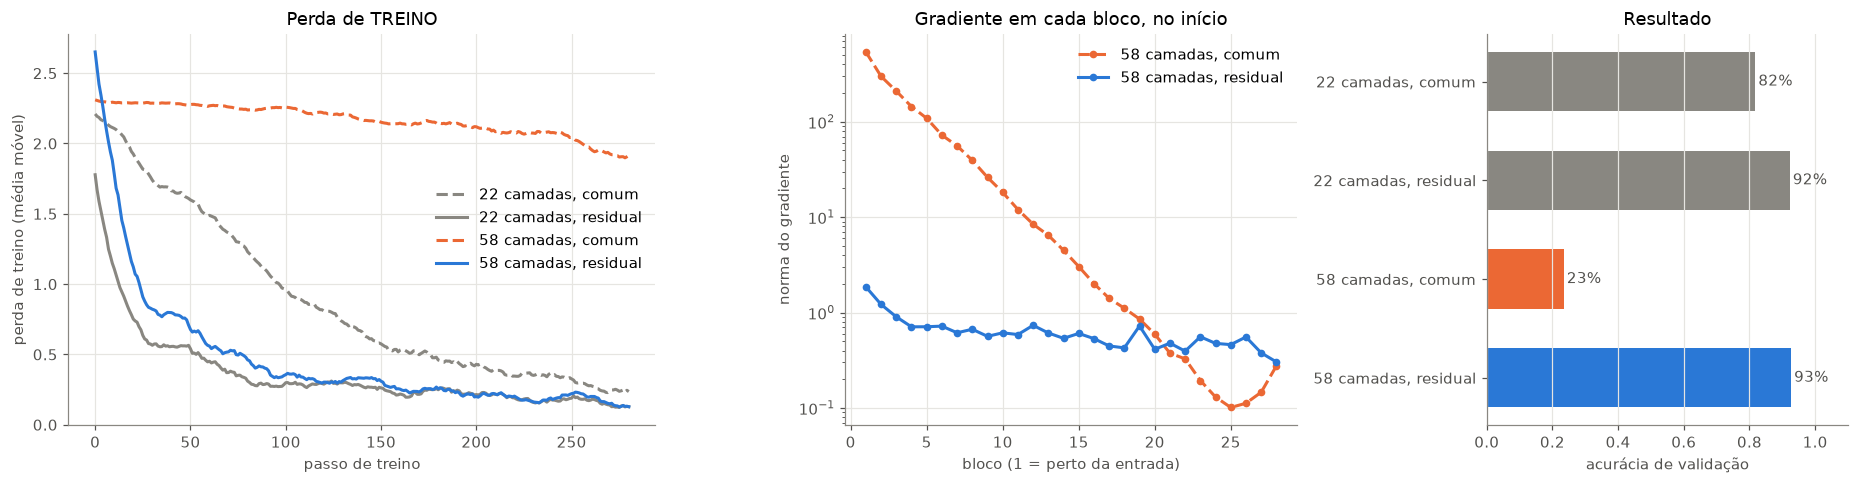

In [18]:
estilos = {"22 camadas, comum": (CINZA, "--"), "22 camadas, residual": (CINZA, "-"),
           "58 camadas, comum": (LARANJA, "--"), "58 camadas, residual": (AZUL, "-")}
suaviza = lambda s, j=20: np.convolve(s, np.ones(j) / j, mode="valid")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), width_ratios=[1.3, 1, 0.8])
for nome, r in resultados.items():
    cor, ls = estilos[nome]
    axes[0].plot(suaviza(r["perdas"]), color=cor, ls=ls, lw=2, label=nome)
axes[0].set(xlabel="passo de treino", ylabel="perda de treino (média móvel)", title="Perda de TREINO")
axes[0].legend(frameon=False)

for nome in ["58 camadas, comum", "58 camadas, residual"]:
    cor, ls = estilos[nome]
    axes[1].plot(range(1, 29), resultados[nome]["grad"], color=cor, ls=ls, lw=2, marker="o", ms=4, label=nome)
axes[1].set(yscale="log", xlabel="bloco (1 = perto da entrada)", ylabel="norma do gradiente",
            title="Gradiente em cada bloco, no início")
axes[1].legend(frameon=False)

nomes = list(resultados)
accs = [resultados[k]["acc"] for k in nomes]
axes[2].barh(nomes[::-1], accs[::-1], color=[estilos[k][0] for k in nomes[::-1]], height=0.6)
for y, v in enumerate(accs[::-1]):
    axes[2].text(v + 0.01, y, f"{v:.0%}", va="center", color=TINTA)
axes[2].set(xlim=(0, 1.1), xlabel="acurácia de validação", title="Resultado")
axes[2].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Leitura:**

- **Sem skip connections, mais camadas pioram a rede**: a de 58 camadas fica muito pior que a de 22, e a perda de
  **treino** dela mal cai. É o *problema da degradação* descrito pelos autores da ResNet.
- O gráfico do meio mostra o porquê: na rede comum de 58 camadas, o gradiente nos primeiros blocos é **descontrolado**
  (milhares de vezes maior que o dos últimos): cada camada distorce um pouco o sinal, e as distorções se multiplicam. Com as skip connections, ele fica estável em toda a profundidade.
- **Com skip connections, a rede de 58 camadas treina tão bem quanto (ou melhor que) a de 22.** Profundidade volta a
  ser uma vantagem, não um obstáculo.

## 2.5 Os blocos da ResNet de verdade

Dois detalhes que aparecem nas ResNets reais:

1. **Atalho com projeção**: quando o bloco muda o número de canais ou reduz o tamanho (`stride=2`), $x$ e $F(x)$
   não têm o mesmo formato e não podem ser somados. A solução é passar $x$ por uma convolução **1 × 1** no atalho.
2. **Bloco *bottleneck*** (ResNet-50 e maiores): `conv 1×1` (reduz canais) → `conv 3×3` → `conv 1×1` (expande).
   Fica mais barato que duas convoluções 3 × 3 com muitos canais.

In [19]:
class BlocoBottleneck(nn.Module):
    """Bloco da ResNet-50: 1×1 (reduz) - 3×3 - 1×1 (expande), com projeção no atalho se necessário."""

    def __init__(self, entrada, meio, saida, stride=1):
        super().__init__()
        self.ramo = nn.Sequential(
            nn.Conv2d(entrada, meio, 1, bias=False), nn.BatchNorm2d(meio), nn.ReLU(),
            nn.Conv2d(meio, meio, 3, stride=stride, padding=1, bias=False), nn.BatchNorm2d(meio), nn.ReLU(),
            nn.Conv2d(meio, saida, 1, bias=False), nn.BatchNorm2d(saida),
        )
        self.atalho = nn.Identity()
        if stride != 1 or entrada != saida:             # formatos diferentes: projeção 1×1 no atalho
            self.atalho = nn.Sequential(nn.Conv2d(entrada, saida, 1, stride=stride, bias=False), nn.BatchNorm2d(saida))

    def forward(self, x):
        return F.relu(self.ramo(x) + self.atalho(x))

x = torch.randn(1, 256, 56, 56)
for nome, bloco in {"mesmo formato (atalho = identidade)": BlocoBottleneck(256, 64, 256),
                    "reduz e aprofunda (atalho = conv 1×1, stride 2)": BlocoBottleneck(256, 128, 512, stride=2)}.items():
    print(f"{nome:<48} {tuple(x.shape)} → {tuple(bloco(x).shape)}   {sum(p.numel() for p in bloco.parameters()):,} parâmetros")

dois_3x3 = 2 * (256 * 256 * 9)
print(f"\ncomparação: duas convoluções 3×3 com 256 canais teriam {dois_3x3:,} parâmetros")

mesmo formato (atalho = identidade)              (1, 256, 56, 56) → (1, 256, 56, 56)   70,400 parâmetros
reduz e aprofunda (atalho = conv 1×1, stride 2)  (1, 256, 56, 56) → (1, 512, 28, 28)   379,392 parâmetros

comparação: duas convoluções 3×3 com 256 canais teriam 1,179,648 parâmetros


## 2.6  *global average pooling*

Lembra que na LeNet e na VGG quase todos os parâmetros estavam nas camadas densas depois do `Flatten`? 

A ResNet troca isso pelo ***global average pooling*** (GAP): tira a **média de cada mapa inteiro**, transformando
`(2048, 7, 7)` em um vetor de 2.048 números, e só então aplica **uma** camada linear.

In [20]:
canais, h, w, classes = 2048, 7, 7, 1000
flatten_denso = canais * h * w * classes
gap_denso = canais * classes
print(f"Flatten (2048 × 7 × 7 = {canais * h * w:,}) → densa de 1000: {flatten_denso:>12,} pesos")
print(f"GAP     (2048)                    → densa de 1000: {gap_denso:>12,} pesos   ({flatten_denso // gap_denso}× menos)")

Flatten (2048 × 7 × 7 = 100,352) → densa de 1000:  100,352,000 pesos
GAP     (2048)                    → densa de 1000:    2,048,000 pesos   (49× menos)


> ### 🗂️ Ficha: ResNet (Residual Network)
>
> | | |
> |---|---|
> | **Ano** | 2015 (He, Zhang, Ren e Sun, Microsoft Research) |
> | **Antiga ou nova?** | **Clássica**: tem 10 anos e ainda é uma das redes mais usadas como ponto de partida |
> | **Tipo de treino** | **supervisionado** no ImageNet; hoje existem versões treinadas de forma auto-supervisionada |
> | **Por que é importante** | as **skip connections** resolveram o problema da degradação e permitiram treinar redes com **50, 101, 152 e até 1.000 camadas**; venceu o ImageNet 2015 (erro top-5 de 3,6%, abaixo do estimado para humanos). A ideia residual está hoje em praticamente toda arquitetura, **inclusive nos Transformers** |
> | **Pontos fortes** | treina de forma estável em grande profundidade; GAP em vez de densas gigantes (ResNet-50 tem ~25 milhões de parâmetros, contra 138 da VGG-16); ótimo *backbone* para outras tarefas (detecção, segmentação) |
> | **Limitações** | continua sendo uma CNN: campo receptivo local, relações de longa distância só nas camadas finais; em grandes volumes de dados, Transformers costumam superá-la |
> | **Ainda é usada?** | **muito**: como *baseline*, como *backbone* de U-Nets e detectores, e em sensoriamento remoto |

# Parte 3 — Hugging Face

## 3.1 O que é o Hugging Face?

O **[Hugging Face](https://huggingface.co)** é o "GitHub dos modelos de IA". O **Hub** hospeda, de forma aberta:

| O quê | Exemplos |
|---|---|
| **Modelos** (mais de um milhão) | ResNets, ViTs, LLMs, modelos de fundação para observação da Terra (Prithvi, Clay, DOFA) |
| **Datasets** | imagens rotuladas, textos, séries temporais, imagens de satélite |
| **Spaces** | aplicativos de demonstração rodando no navegador |

Cada modelo tem um ***model card***: quem treinou, com que dados, licença, métricas e como usar. Em vez de treinar uma
ResNet-50 do zero (dias de GPU no ImageNet), baixamos os pesos prontos em segundos.

Bibliotecas que conversam com o Hub:

| Biblioteca | Para quê |
|---|---|
| `huggingface_hub` | buscar, baixar e enviar arquivos, modelos e datasets |
| `timm` (*PyTorch Image Models*) | centenas de arquiteturas de visão (ResNet, ConvNeXt, ViT, DINOv2) com pesos pré-treinados |
| `transformers` | modelos de linguagem, de visão e multimodais |
| `datasets` | carregar datasets do Hub com uma linha |

## 3.2 Criando uma conta e se conectando

Para **baixar** modelos e datasets públicos, você **não precisa de conta**. A conta e um **token** são necessários para:
modelos privados ou com acesso restrito (*gated*, como alguns LLMs), **enviar** seus próprios modelos e datasets, e ter
limites de download maiores.

1. Crie uma conta em [huggingface.co/join](https://huggingface.co/join).
2. Gere um token em **Settings → Access Tokens** ([huggingface.co/settings/tokens](https://huggingface.co/settings/tokens)):
   tipo **Read** para baixar, **Write** para enviar.
3. Conecte-se de **uma** destas formas:
   - no terminal: `hf auth login` (o token fica salvo no computador);
   - no notebook: `from huggingface_hub import login; login()`;
   - pela variável de ambiente `HF_TOKEN` (por exemplo no seu `.env`). **Nunca** coloque o token no código ou no GitHub.

Sem token, o Hub mostra um aviso pedindo um `HF_TOKEN` para ter limites maiores. Para esta aula pode ignorar (deixamos
o aviso desligado no início do notebook).

In [21]:
from huggingface_hub import HfApi, hf_hub_download, whoami

if os.environ.get("HF_TOKEN"):
    print(f"conectado ao Hugging Face como: {whoami()['name']}")
else:
    print("sem token: tudo bem para baixar modelos e datasets públicos (o caso desta aula)")

sem token: tudo bem para baixar modelos e datasets públicos (o caso desta aula)


## 3.3 Explorando o Hub pelo Python

A mesma busca do site pode ser feita no código. As ResNet-50 do `timm` mais baixadas:

In [22]:
api = HfApi()
for modelo in api.list_models(search="resnet50", filter="timm", sort="downloads", limit=6):
    print(f"{modelo.id:<45} {modelo.downloads:>12,} downloads")

timm/resnet50.a1_in1k                            1,487,127 downloads
timm/wide_resnet50_2.racm_in1k                     613,770 downloads
timm/resnet50.fb_swsl_ig1b_ft_in1k                 163,749 downloads
timm/resnet50d.ra2_in1k                            123,581 downloads
timm/resnet50_gn.a1h_in1k                           60,670 downloads
timm/resnet50.tv_in1k                               35,150 downloads


## 3.4 Baixando um dataset do Hub

Para o estudo de caso vamos usar o **LandCover.ai**: ortofotos aéreas da Polônia (25–50 cm por pixel) com máscaras de
**5 classes** (fundo, edificação, floresta, água, estrada). A versão `isaaccorley/landcoverai` tem 100 recortes de
512 × 512 pixels (70 de treino, 15 de validação, 15 de teste), em um zip de 9 MB.

`hf_hub_download` baixa o arquivo para um **cache** local: na segunda vez, não baixa de novo.

> Fonte: Boguszewski et al. (2021), *LandCover.ai*, licença CC BY-NC-SA 4.0 (uso não comercial).

In [23]:
caminho_zip = hf_hub_download(repo_id="isaaccorley/landcoverai", filename="landcoverai100.zip", repo_type="dataset")
print(f"arquivo no cache: {caminho_zip}")

PASTA_LC = "data/landcoverai"
if not os.path.exists(PASTA_LC):
    zipfile.ZipFile(caminho_zip).extractall(PASTA_LC)
ids = {s: open(f"{PASTA_LC}/{s}.txt").read().split() for s in ["train", "val", "test"]}
print({s: len(v) for s, v in ids.items()})

arquivo no cache: /Users/macuser/.cache/huggingface/hub/datasets--isaaccorley--landcoverai/snapshots/5cdf9299bd6c1232506cf79373df01f6e6596b50/landcoverai100.zip


{'train': 70, 'val': 15, 'test': 15}


## 3.5 Carregando uma ResNet-50 pré-treinada

Com o `timm`, carregar um modelo do Hub é uma linha: o prefixo `hf-hub:` diz de onde baixar. Usamos o
**`timm/resnet50.a1_in1k`**: uma ResNet-50 treinada de forma **supervisionada** no ImageNet-1k (1.000 classes) com a
receita moderna "A1" do artigo *ResNet strikes back* (2021).

In [24]:
import timm
from timm.data import ImageNetInfo

inicio = time.time()
resnet50 = timm.create_model("hf-hub:timm/resnet50.a1_in1k", pretrained=True).eval()
print(f"carregada em {time.time() - inicio:.0f} s: {sum(p.numel() for p in resnet50.parameters()) / 1e6:.1f} milhões de parâmetros")

# o próprio modelo informa como as imagens devem ser preparadas (tamanho, normalização)
config = timm.data.resolve_data_config({}, model=resnet50)
transformacao = timm.data.create_transform(**config)
print(config)

carregada em 1 s: 25.6 milhões de parâmetros
{'input_size': [3, 224, 224], 'interpolation': 'bicubic', 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225], 'crop_pct': 0.95, 'crop_mode': 'center'}


Vamos classificar quatro imagens: três fotos do `scikit-image` e um recorte **aéreo** do LandCover.ai.

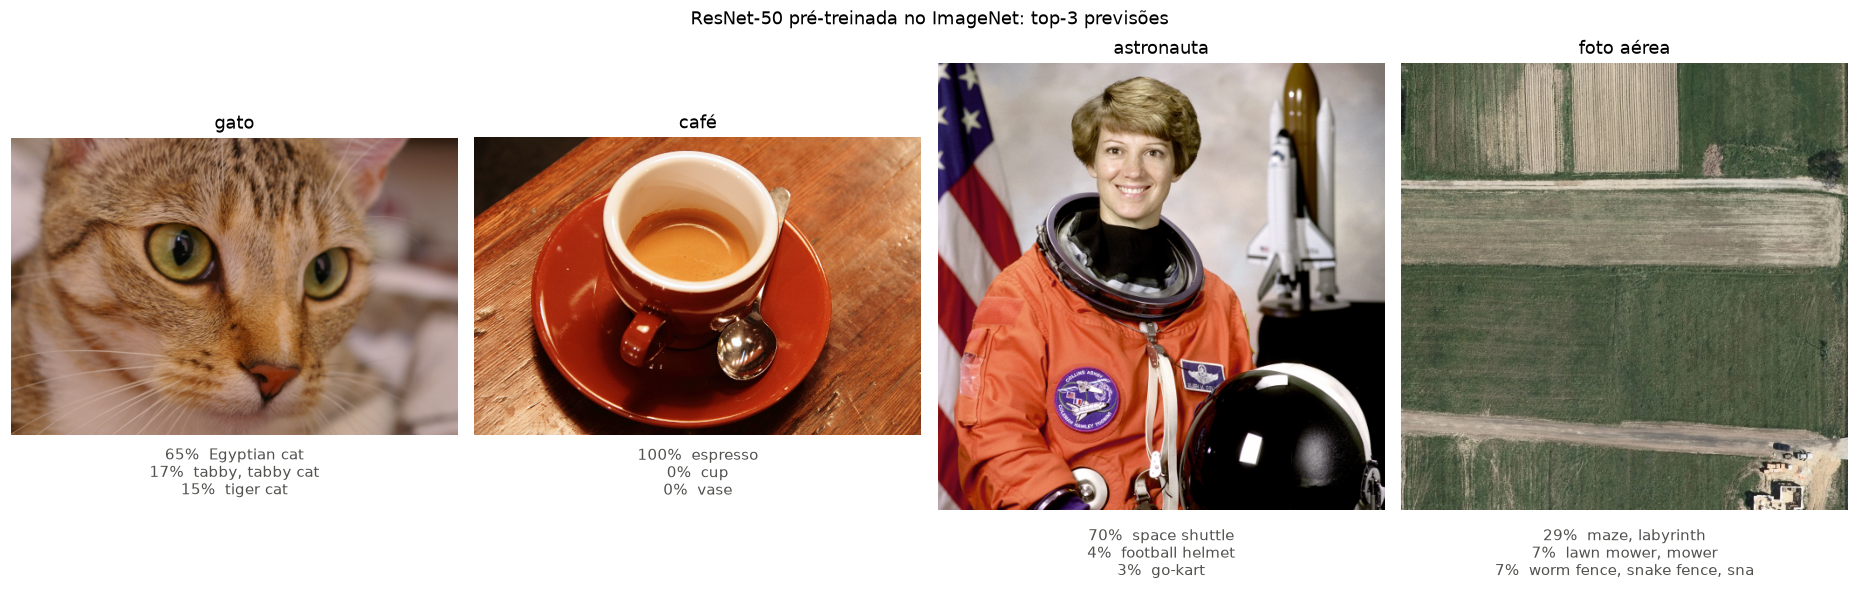

In [25]:
classes_imagenet = ImageNetInfo()
imagens = {
    "gato": data.chelsea(),
    "café": data.coffee(),
    "astronauta": data.astronaut(),
    "foto aérea": io.imread(f"{PASTA_LC}/output/{ids['test'][0]}.jpg"),
}

fig, axes = plt.subplots(1, 4, figsize=(17, 5))
for ax, (nome, img) in zip(axes, imagens.items()):
    x = transformacao(Image.fromarray(img)).unsqueeze(0)
    with torch.no_grad():
        prob = resnet50(x).softmax(dim=1)[0]
    top = prob.topk(3)
    texto = "\n".join(f"{p:.0%}  {classes_imagenet.index_to_description(int(i))[:28]}" for p, i in zip(top.values, top.indices))
    ax.imshow(img)
    ax.set_title(nome, fontsize=12)
    ax.text(0.5, -0.04, texto, transform=ax.transAxes, ha="center", va="top", fontsize=9.5, color=TINTA)
    ax.axis("off")
plt.suptitle("ResNet-50 pré-treinada no ImageNet: top-3 previsões", y=0.98)
plt.tight_layout()
plt.show()

Para fotos do dia a dia, a ResNet-50 acerta ou chega perto: o ImageNet não tem a classe "astronauta", então ela
aponta o ônibus espacial ao fundo. Para a **foto aérea**, as previsões não fazem sentido: o
ImageNet tem 1.000 classes de objetos fotografados de lado (cães, xícaras, carros), e nenhuma delas é "floresta vista
de cima" ou "telhado". É uma **mudança de domínio** (*domain shift*).

Isso significa que a ResNet-50 é inútil para imagens aéreas? **Não.** Os filtros das primeiras camadas detectam bordas,
texturas e cores, coisas que existem em qualquer imagem. Veja os 64 filtros 7 × 7 da primeira camada:

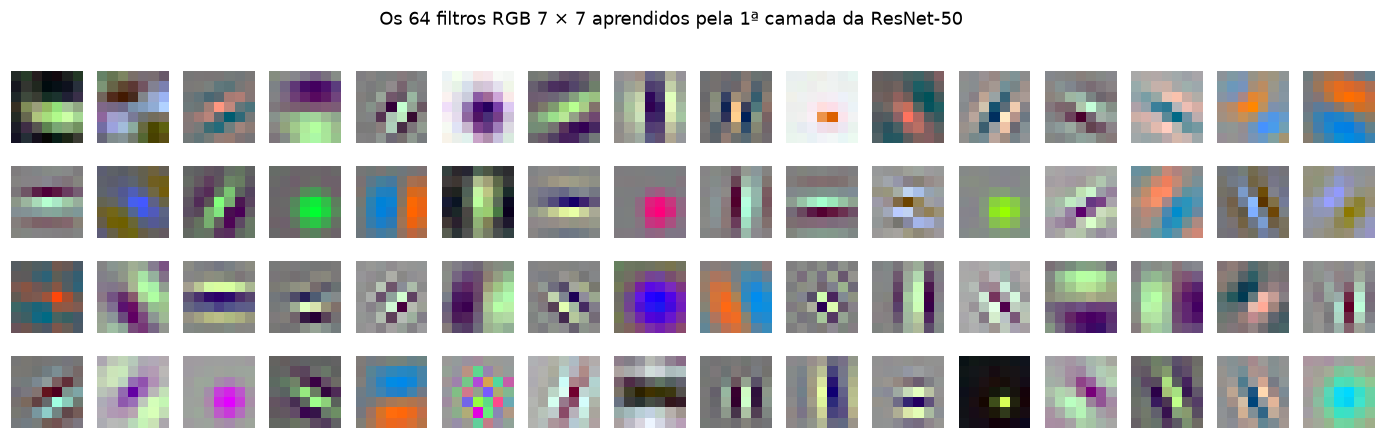

In [26]:
filtros = resnet50.conv1.weight.detach()                          # (64, 3, 7, 7)
filtros = (filtros - filtros.amin(dim=(1, 2, 3), keepdim=True)) / (filtros.amax(dim=(1, 2, 3), keepdim=True) - filtros.amin(dim=(1, 2, 3), keepdim=True))

fig, axes = plt.subplots(4, 16, figsize=(16, 4.3))
for ax, f in zip(axes.flat, filtros):
    ax.imshow(f.permute(1, 2, 0))
    ax.axis("off")
plt.suptitle("Os 64 filtros RGB 7 × 7 aprendidos pela 1ª camada da ResNet-50", y=1.0)
plt.show()

Bordas em várias direções, manchas de cor, padrões listrados: a rede **aprendeu sozinha** filtros muito parecidos com
os da seção 1.3. Essas características genéricas são exatamente o que queremos reaproveitar. Esse é o princípio da
**transferência de aprendizado** (*transfer learning*).

Na Parte 4 vamos colocar essas características para trabalhar em um problema de segmentação de imagens aéreas.

# Parte 4 — U-Net: segmentação semântica

Até aqui, todas as redes **classificaram imagens inteiras**: "esta imagem é um 7", "esta imagem é um gato". Em
sensoriamento remoto, quase sempre queremos mais: **onde** está a floresta, **quais pixels** são água, **onde** estão
as edificações. Isso é **segmentação semântica**: uma classe para **cada pixel**.

| Tarefa | Pergunta | Saída da rede |
|---|---|---|
| Classificação | "o que há nesta imagem?" | um vetor de classes: `(lote, n_classes)` |
| **Segmentação semântica** | "a que classe pertence cada pixel?" | um mapa de classes: `(lote, n_classes, H, W)` |

Para isso a rede precisa fazer duas coisas que parecem contraditórias: **entender o contexto** (o que exige reduzir a
imagem, como faz a ResNet) e **devolver a resolução original**, pixel a pixel. A U-Net resolve as duas.

> ### 🗂️ Ficha: U-Net
>
> | | |
> |---|---|
> | **Ano** | 2015 (Ronneberger, Fischer e Brox), criada para segmentar células em imagens de microscopia |
> | **Antiga ou nova?** | **Clássica**, mas continua no estado da arte de segmentação; é também a base dos modelos de difusão que geram imagens |
> | **Tipo de treino** | **supervisionado**: cada pixel da imagem tem um rótulo (máscara de segmentação) |
> | **Por que é importante** | resolveu a **segmentação semântica** (uma classe por pixel) com poucas imagens rotuladas; virou o padrão em medicina e em **sensoriamento remoto** (uso do solo, edificações, água, desmatamento, queimadas) |
> | **Pontos fortes** | formato em **U**: o *encoder* entende **o que** há na imagem, o *decoder* recupera **onde**; as **skip connections longas** levam os detalhes finos do encoder direto ao decoder; aceita qualquer *backbone* pré-treinado como encoder |
> | **Limitações** | precisa de máscaras rotuladas pixel a pixel (caras de produzir); o decoder pode ser pesado em imagens grandes; contexto global limitado pelo encoder convolucional |
> | **Ainda é usada?** | **muito**: é provavelmente a arquitetura mais usada em segmentação de imagens de satélite |

## 4.1 A arquitetura

A U-Net tem a forma de um **U**:

- **Encoder** (lado esquerdo, descendo): blocos de convolução + *max pooling*. A imagem fica **menor** e mais **profunda**
  (mais canais): a rede entende **o que** há na imagem, mas perde **onde** exatamente.
- **Decoder** (lado direito, subindo): convoluções transpostas dobram o tamanho a cada passo até voltar à resolução original.
- **Skip connections** (as pontes do U): o mapa de cada nível do encoder é **concatenado** ao nível correspondente do
  decoder, devolvendo os **detalhes finos** (bordas de casas, estradas estreitas) que o pooling apagou.

```
 entrada (3, 256, 256)                                                     saída (5, 256, 256)
   │                                                                            ▲ conv 1×1
 enc1  DuplaConv → (16, 256, 256) ──────────── skip ────────────►  dec1  concat + DuplaConv → (16, 256, 256)
   │ max pool                                                                   ▲ ConvTranspose 2×2
 enc2  DuplaConv → (32, 128, 128) ────────── skip ──────────►  dec2  concat + DuplaConv → (32, 128, 128)
   │ max pool                                                                   ▲
 enc3  DuplaConv → (64, 64, 64) ──────── skip ────────►  dec3  concat + DuplaConv → (64, 64, 64)
   │ max pool                                                                   ▲
 enc4  DuplaConv → (128, 32, 32) ────── skip ──────►  dec4  concat + DuplaConv → (128, 32, 32)
   │ max pool                                                                   ▲
   └───────────────────────► fundo  DuplaConv → (256, 16, 16) ──────────────────┘
```

Três peças de código:

| Peça | O que faz |
|---|---|
| `DuplaConv` | duas convoluções 3 × 3, cada uma com BatchNorm e ReLU: o "tijolo" da U-Net |
| `nn.MaxPool2d(2)` | desce um nível: metade da altura e da largura |
| `Subida` | `nn.ConvTranspose2d` (uma convolução que **aumenta** a imagem, com pesos aprendidos) + concatenação com a skip + `DuplaConv` |

In [ ]:
class DuplaConv(nn.Sequential):
    """conv 3×3 → BatchNorm → ReLU, duas vezes. Mantém a altura e a largura."""
    def __init__(self, entrada, saida):
        super().__init__(
            nn.Conv2d(entrada, saida, 3, padding=1, bias=False), nn.BatchNorm2d(saida), nn.ReLU(inplace=True),
            nn.Conv2d(saida, saida, 3, padding=1, bias=False), nn.BatchNorm2d(saida), nn.ReLU(inplace=True),
        )


class Decoder(nn.Module):
    """Dobra o tamanho, concatena a skip connection do encoder e aplica uma DuplaConv."""
    def __init__(self, entrada, saida):
        super().__init__()
        self.sobe = nn.ConvTranspose2d(entrada, saida, kernel_size=2, stride=2)
        self.conv = DuplaConv(2 * saida, saida)        # 2×: os canais que sobem + os canais da skip

    def forward(self, x, skip):
        x = self.sobe(x)
        x = torch.cat([x, skip], dim=1)               # a skip connection da U-Net: concatenação de canais
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, canais_entrada=3, n_classes=5, base=16):
        super().__init__()
        c = [base, 2 * base, 4 * base, 8 * base, 16 * base]     # 16, 32, 64, 128, 256 canais
        self.pool = nn.MaxPool2d(2)
        self.enc1, self.enc2 = DuplaConv(canais_entrada, c[0]), DuplaConv(c[0], c[1])
        self.enc3, self.enc4 = DuplaConv(c[1], c[2]), DuplaConv(c[2], c[3])
        self.fundo = DuplaConv(c[3], c[4])
        self.dec4, self.dec3 = Decoder(c[4], c[3]), Decoder(c[3], c[2])
        self.dec2, self.dec1 = Decoder(c[2], c[1]), Decoder(c[1], c[0])
        self.saida = nn.Conv2d(c[0], n_classes, kernel_size=1)   # um "logit" por classe em cada pixel

    def forward(self, x, mostra=False):
        e1 = self.enc1(x)                     # encoder: desce
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        f = self.fundo(self.pool(e4))
        d4 = self.dec4(f, e4)                 # decoder: sobe, recebendo as skips
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)
        y = self.saida(d1)
        if mostra:
            for nome, t in [("entrada", x), ("enc1", e1), ("enc2", e2), ("enc3", e3), ("enc4", e4), ("fundo", f),
                            ("dec4", d4), ("dec3", d3), ("dec2", d2), ("dec1", d1), ("saída", y)]:
                print(f"{nome:<8} {str(tuple(t.shape)):<22}")
        return y


unet = UNet()
with torch.no_grad():
    unet(torch.zeros(1, 3, 256, 256), mostra=True)
print(f"\nparâmetros: {sum(p.numel() for p in unet.parameters()):,}  "
      f"(a U-Net do artigo original, com base=64, teria {sum(p.numel() for p in UNet(base=64).parameters()):,})")

entrada  (1, 3, 256, 256)      
enc1     (1, 16, 256, 256)     
enc2     (1, 32, 128, 128)     
enc3     (1, 64, 64, 64)       
enc4     (1, 128, 32, 32)      
fundo    (1, 256, 16, 16)      
dec4     (1, 128, 32, 32)      
dec3     (1, 64, 64, 64)       
dec2     (1, 32, 128, 128)     
dec1     (1, 16, 256, 256)     
saída    (1, 5, 256, 256)      

parâmetros: 1,942,645  (a U-Net do artigo original, com base=64, teria 31,037,893)


Repare no formato em **U** nos números: a altura vai de 256 até 16 no fundo e volta a 256, enquanto os canais vão de 16
a 256 e voltam. A saída tem **5 canais** (um por classe) com o **mesmo tamanho da entrada**.

## 4.2 Como usar uma U-Net

### Os dados

Usamos o LandCover.ai baixado na Parte 3: 100 ortofotos da Polônia com máscaras de 5 classes. Reduzimos as imagens
de 512 para 256 pixels para treinar rápido.

In [28]:
NOMES_LC = ["fundo", "edificação", "floresta", "água", "estrada"]
CORES_LC = ["#d9d9d9", "#e34948", "#1baf7a", "#2a78d6", "#eda100"]
cmap_lc = ListedColormap(CORES_LC)
TAMANHO = 256          # reduzimos de 512 para 256 para treinar rápido

def carrega_split(split):
    imgs = np.stack([io.imread(f"{PASTA_LC}/output/{i}.jpg") for i in ids[split]])
    mascaras = np.stack([io.imread(f"{PASTA_LC}/output/{i}_m.png")[..., 0] for i in ids[split]])
    X = torch.tensor(imgs).permute(0, 3, 1, 2).float() / 255                       # (N, 3, 512, 512)
    Y = torch.tensor(mascaras).long()                                              # (N, 512, 512)
    X = F.interpolate(X, size=TAMANHO, mode="bilinear", antialias=True)
    Y = F.interpolate(Y[:, None].float(), size=TAMANHO, mode="nearest")[:, 0].long()   # máscara: vizinho mais próximo
    return X, Y

X_tr, Y_tr = carrega_split("train")
X_te, Y_te = carrega_split("test")
# a mesma normalização usada no pré-treino da ResNet-50 (ImageNet)
media, desvio = torch.tensor(config["mean"])[:, None, None], torch.tensor(config["std"])[:, None, None]
normaliza = lambda x: (x - media) / desvio
print(f"treino: {tuple(X_tr.shape)} {tuple(Y_tr.shape)}   teste: {tuple(X_te.shape)}")

frac = torch.bincount(Y_tr.flatten(), minlength=5) / Y_tr.numel()
print("fração de pixels por classe:", {n: f"{f:.1%}" for n, f in zip(NOMES_LC, frac)})

treino: (70, 3, 256, 256) (70, 256, 256)   teste: (15, 3, 256, 256)
fração de pixels por classe: {'fundo': '63.4%', 'edificação': '1.3%', 'floresta': '29.2%', 'água': '4.0%', 'estrada': '2.0%'}


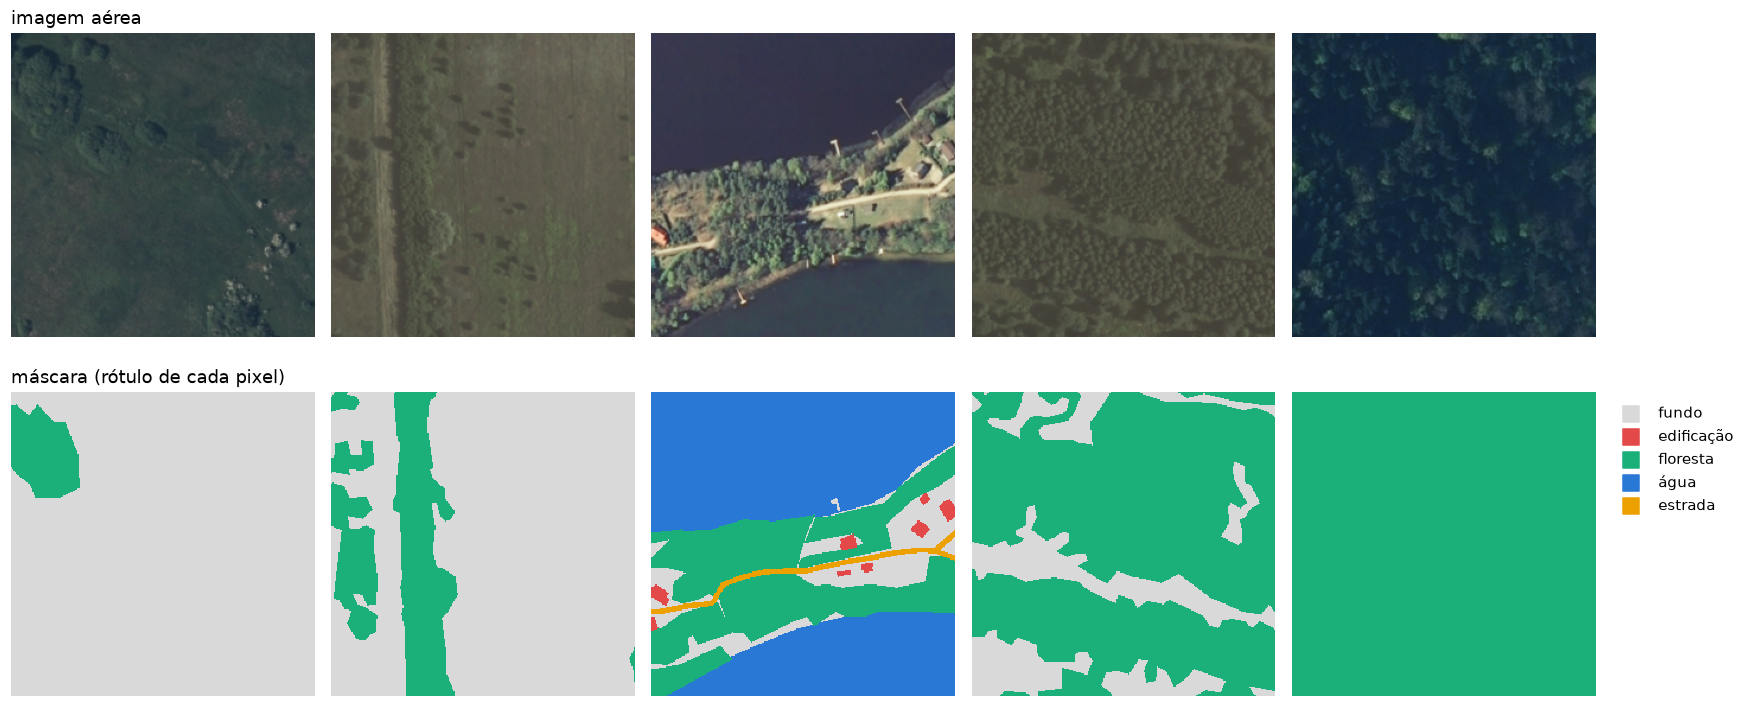

In [29]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.8))
for k, idx in enumerate([0, 7, 14, 21, 35]):
    axes[0, k].imshow(X_tr[idx].permute(1, 2, 0))
    axes[1, k].imshow(Y_tr[idx], cmap=cmap_lc, vmin=0, vmax=4, interpolation="nearest")
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].set_title("imagem aérea", loc="left")
axes[1, 0].set_title("máscara (rótulo de cada pixel)", loc="left")
for nome, cor in zip(NOMES_LC, CORES_LC):
    axes[1, 4].scatter([], [], marker="s", s=120, color=cor, label=nome)
axes[1, 4].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Da saída da rede à máscara

A U-Net devolve, para cada pixel, **5 logits** (um por classe). O caminho até a máscara é o mesmo da classificação,
só que aplicado a cada pixel:

1. `softmax` na dimensão das classes (`dim=1`) → probabilidades que somam 1 **em cada pixel**;
2. `argmax` na mesma dimensão → a classe mais provável de cada pixel = a **máscara prevista**.

A perda também é a mesma entropia cruzada da classificação, calculada em **cada pixel** e depois tirada a média. O
`F.cross_entropy` aceita isso direto: logits `(lote, classes, H, W)` e rótulos `(lote, H, W)`.

entrada (4, 3, 256, 256) → logits (4, 5, 256, 256) → máscara (4, 256, 256)
soma das probabilidades em um pixel qualquer: 1.000
perda da rede ainda NÃO treinada: 1.874   (um chute uniforme entre 5 classes daria ln 5 = 1.609)


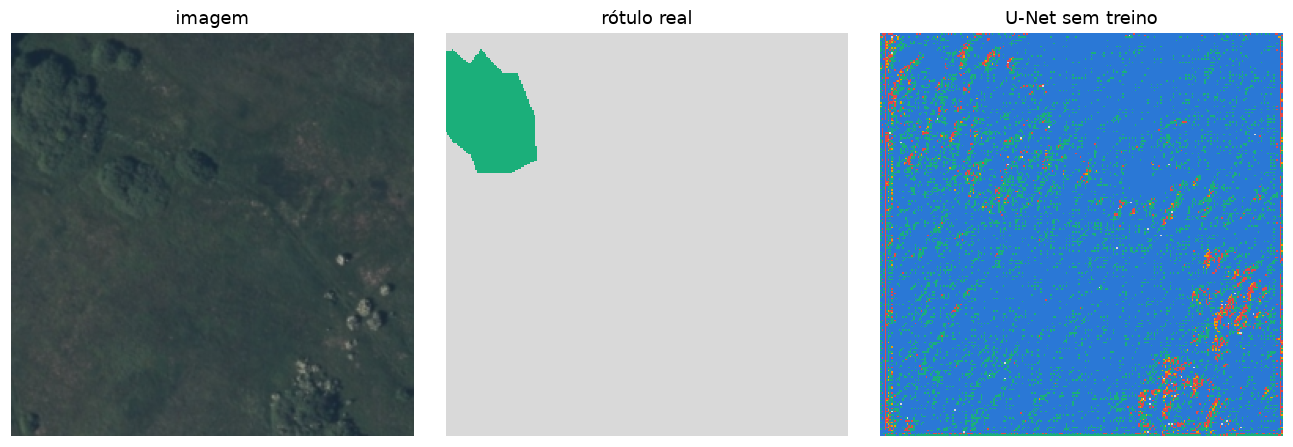

In [30]:
torch.manual_seed(0)
unet = UNet()
x, y = normaliza(X_tr[:4]), Y_tr[:4]

with torch.no_grad():
    logits = unet(x)                              # (4, 5, 256, 256)
    probs = logits.softmax(dim=1)                 # probabilidades por pixel
    mascara = probs.argmax(dim=1)                 # (4, 256, 256): a classe de cada pixel
    perda = F.cross_entropy(logits, y)            # média da entropia cruzada em todos os pixels

print(f"entrada {tuple(x.shape)} → logits {tuple(logits.shape)} → máscara {tuple(mascara.shape)}")
print(f"soma das probabilidades em um pixel qualquer: {probs[0, :, 100, 100].sum():.3f}")
print(f"perda da rede ainda NÃO treinada: {perda:.3f}   (um chute uniforme entre 5 classes daria ln 5 = {np.log(5):.3f})")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(X_tr[0].permute(1, 2, 0)); axes[0].set_title("imagem")
axes[1].imshow(Y_tr[0], cmap=cmap_lc, vmin=0, vmax=4, interpolation="nearest"); axes[1].set_title("rótulo real")
axes[2].imshow(mascara[0], cmap=cmap_lc, vmin=0, vmax=4, interpolation="nearest"); axes[2].set_title("U-Net sem treino")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4.3 Treinando a U-Net do zero

O laço de treino é o de sempre (aula 4). Duas particularidades da segmentação:

- a perda é calculada **em cada pixel**;
- o **aumento de dados** precisa ser aplicado **igual** na imagem e na máscara. Como as fotos são vistas de cima,
  usamos rotações de 90°: uma floresta girada continua sendo uma floresta.

A função abaixo treina **só os parâmetros com `requires_grad=True`**: vamos reaproveitá-la na seção 4.4 com um
encoder congelado. (Cerca de 1 minuto na GPU, 2–3 na CPU.)

In [31]:
def treina_segmentacao(modelo, epocas=20, lote=8, lr=1e-3, nome=""):
    torch.manual_seed(0)
    modelo = modelo.to(DEVICE)
    otimizador = torch.optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=lr)
    gerador = torch.Generator().manual_seed(0)
    historico, inicio = [], time.time()
    for epoca in range(epocas):
        modelo.train()
        perdas = []
        for idx in torch.randperm(len(X_tr), generator=gerador).split(lote):
            x, y = normaliza(X_tr[idx]), Y_tr[idx]
            k = int(torch.randint(0, 4, (1,), generator=gerador))         # rotação de k × 90°, igual na imagem e na máscara
            x, y = torch.rot90(x, k, dims=(2, 3)), torch.rot90(y, k, dims=(1, 2))
            otimizador.zero_grad()
            perda = F.cross_entropy(modelo(x.to(DEVICE)), y.to(DEVICE))
            perda.backward()
            otimizador.step()
            perdas.append(perda.item())
        historico.append(np.mean(perdas))
    print(f"{nome:<32} perda final = {historico[-1]:.3f}   ({time.time() - inicio:.0f} s)")
    return modelo.eval(), historico


torch.manual_seed(0)
unet_zero, hist_zero = treina_segmentacao(UNet(), nome="U-Net do zero")

U-Net do zero                    perda final = 0.679   (50 s)


## 4.4 U-Net com encoder pré-treinado (ResNet-50 do Hugging Face)

Com apenas 70 imagens, aprender **tudo do zero** é difícil: o encoder precisa descobrir sozinho o que são bordas,
texturas e formas. A ideia da **transferência de aprendizado**: trocar o encoder da U-Net pela **ResNet-50 pré-treinada**
da Parte 3, que já sabe extrair essas características, e treinar **só o decoder**.

O `timm` entrega o encoder pronto com `features_only=True`: em vez da classificação, a ResNet-50 devolve os mapas de
**5 profundidades**, exatamente os níveis que a U-Net precisa para as skip connections.

```
 imagem 256×256                                                        máscara 256×256 (5 classes)
     │                                                                        ▲
 ┌───▼──────────── ENCODER (ResNet-50 pré-treinada, congelada) ┐   ┌─── DECODER (treinado) ───┴───┐
 │  64 canais, 128×128  ─────────────── skip ───────────────────────►  concat → conv → 32 canais  │
 │  256 canais,  64×64  ─────────────── skip ───────────────────────►  concat → conv → 64 canais  │
 │  512 canais,  32×32  ─────────────── skip ───────────────────────►  concat → conv → 128 canais │
 │ 1024 canais,  16×16  ─────────────── skip ───────────────────────►  concat → conv → 256 canais │
 │ 2048 canais,   8×8   ─────────────── (fundo do U) ───────────────►  sobe (upsample) ×2        │
 └─────────────────────────────────────────────────────────────┘   └──────────────────────────────┘
```

Repare na diferença entre as duas *skip connections* que vimos nesta aula:

| | ResNet | U-Net |
|---|---|---|
| Distância | **curta**: pula 2 ou 3 camadas | **longa**: liga o encoder ao decoder |
| Operação | **soma** (`F(x) + x`) | **concatenação** de canais (`torch.cat`) |
| Objetivo | o gradiente fluir em redes profundas | recuperar os **detalhes espaciais** perdidos no pooling |

In [32]:
encoder_teste = timm.create_model("hf-hub:timm/resnet50.a1_in1k", pretrained=True, features_only=True)
with torch.no_grad():
    for mapa, reducao in zip(encoder_teste(torch.zeros(1, 3, TAMANHO, TAMANHO)), encoder_teste.feature_info.reduction()):
        print(f"{str(tuple(mapa.shape)):<22} (1/{reducao} do tamanho)")
del encoder_teste

(1, 64, 128, 128)      (1/2 do tamanho)
(1, 256, 64, 64)       (1/4 do tamanho)
(1, 512, 32, 32)       (1/8 do tamanho)
(1, 1024, 16, 16)      (1/16 do tamanho)
(1, 2048, 8, 8)        (1/32 do tamanho)


In [33]:
def bloco_decoder(entrada, saida):
    return nn.Sequential(
        nn.Conv2d(entrada, saida, 3, padding=1, bias=False), nn.BatchNorm2d(saida), nn.ReLU(inplace=True),
        nn.Conv2d(saida, saida, 3, padding=1, bias=False), nn.BatchNorm2d(saida), nn.ReLU(inplace=True),
    )


class UNetResNet50(nn.Module):
    def __init__(self, pre_treinado=True, n_classes=5):
        super().__init__()
        self.encoder = timm.create_model("hf-hub:timm/resnet50.a1_in1k", pretrained=pre_treinado, features_only=True)
        for p in self.encoder.parameters():          # encoder CONGELADO: só o decoder aprende
            p.requires_grad = False
        self.dec4 = bloco_decoder(2048 + 1024, 256)
        self.dec3 = bloco_decoder(256 + 512, 128)
        self.dec2 = bloco_decoder(128 + 256, 64)
        self.dec1 = bloco_decoder(64 + 64, 32)
        self.dec0 = bloco_decoder(32, 16)
        self.cabeca = nn.Conv2d(16, n_classes, kernel_size=1)   # 1 canal por classe

    def forward(self, x):
        self.encoder.eval()                          # BatchNorm do encoder em modo de avaliação (congelado)
        with torch.no_grad():
            f1, f2, f3, f4, f5 = self.encoder(x)     # 1/2, 1/4, 1/8, 1/16, 1/32
        sobe = lambda t: F.interpolate(t, scale_factor=2, mode="bilinear", align_corners=False)
        x = self.dec4(torch.cat([sobe(f5), f4], dim=1))   # skip connection = concatenação
        x = self.dec3(torch.cat([sobe(x), f3], dim=1))
        x = self.dec2(torch.cat([sobe(x), f2], dim=1))
        x = self.dec1(torch.cat([sobe(x), f1], dim=1))
        x = self.dec0(sobe(x))
        return self.cabeca(x)                         # (lote, 5, 256, 256): um "logit" por classe e por pixel


torch.manual_seed(0)
unet50 = UNetResNet50()
treinaveis = sum(p.numel() for p in unet50.parameters() if p.requires_grad)
congelados = sum(p.numel() for p in unet50.parameters() if not p.requires_grad)
print(f"encoder congelado: {congelados / 1e6:.1f} M parâmetros | decoder treinável: {treinaveis / 1e6:.1f} M parâmetros")
unet_pre, hist_pre = treina_segmentacao(unet50, nome="U-Net + ResNet-50 pré-treinada")

encoder congelado: 23.5 M parâmetros | decoder treinável: 9.0 M parâmetros


U-Net + ResNet-50 pré-treinada   perda final = 0.471   (48 s)


## 4.5 Avaliação no teste

Em segmentação, a métrica mais usada é o **IoU** (*Intersection over Union*) de cada classe: a área onde previsão e
rótulo concordam, dividida pela área total que qualquer um dos dois marcou. O **mIoU** é a média entre as classes.
A acurácia por pixel engana: um modelo que chuta "fundo" em tudo já acerta ~60% dos pixels.

$$\text{IoU}_c = \frac{|\text{previsto}_c \cap \text{real}_c|}{|\text{previsto}_c \cup \text{real}_c|}$$

In [34]:
@torch.no_grad()
def prediz(modelo, X):
    return torch.cat([modelo(normaliza(X[i:i + 5]).to(DEVICE)).argmax(dim=1).cpu() for i in range(0, len(X), 5)])

def iou_por_classe(pred, real):
    return [((pred == c) & (real == c)).sum().item() / max(((pred == c) | (real == c)).sum().item(), 1) for c in range(5)]

modelos_seg = {"U-Net do zero": unet_zero, "U-Net + ResNet-50 pré-treinada": unet_pre}
predicoes = {nome: prediz(m, X_te) for nome, m in modelos_seg.items()}
avaliacao = pd.DataFrame({nome: iou_por_classe(p, Y_te) + [(p == Y_te).float().mean().item()] for nome, p in predicoes.items()},
                         index=[f"IoU {c}" for c in NOMES_LC] + ["acurácia por pixel"])
avaliacao.loc["mIoU"] = avaliacao.iloc[:5].mean()
avaliacao.round(3)

,U-Net do zero,U-Net + ResNet-50 pré-treinada
IoU fundo,0.775,0.906
IoU edificação,0.000,0.000
IoU floresta,0.437,0.870
IoU água,0.000,0.656
IoU estrada,0.000,0.091
acurácia por pixel,0.735,0.919
mIoU,0.242,0.505


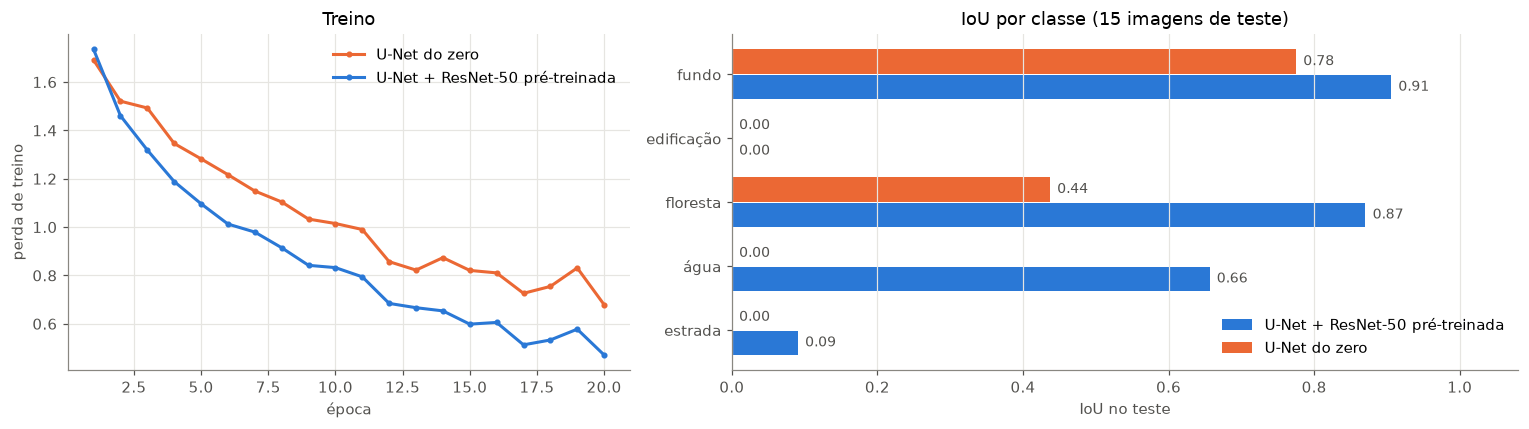

In [35]:
cores_modelos = {"U-Net do zero": LARANJA, "U-Net + ResNet-50 pré-treinada": AZUL}
fig, axes = plt.subplots(1, 2, figsize=(14, 4), width_ratios=[1, 1.4])
for nome, hist in [("U-Net do zero", hist_zero), ("U-Net + ResNet-50 pré-treinada", hist_pre)]:
    axes[0].plot(range(1, len(hist) + 1), hist, color=cores_modelos[nome], lw=2, marker="o", ms=3, label=nome)
axes[0].set(xlabel="época", ylabel="perda de treino", title="Treino")
axes[0].legend(frameon=False)

ious = avaliacao.loc[[f"IoU {c}" for c in NOMES_LC]]
y = np.arange(5)
for desloc, nome in [(0.2, "U-Net + ResNet-50 pré-treinada"), (-0.2, "U-Net do zero")]:
    axes[1].barh(y + desloc, ious[nome], height=0.38, color=cores_modelos[nome], label=nome)
    for yy, v in enumerate(ious[nome]):
        axes[1].text(v + 0.01, yy + desloc, f"{v:.2f}", va="center", fontsize=9, color=TINTA)
axes[1].set(yticks=y, yticklabels=NOMES_LC, xlim=(0, 1.08), xlabel="IoU no teste", title="IoU por classe (15 imagens de teste)")
axes[1].invert_yaxis()
axes[1].grid(axis="y", visible=False)
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

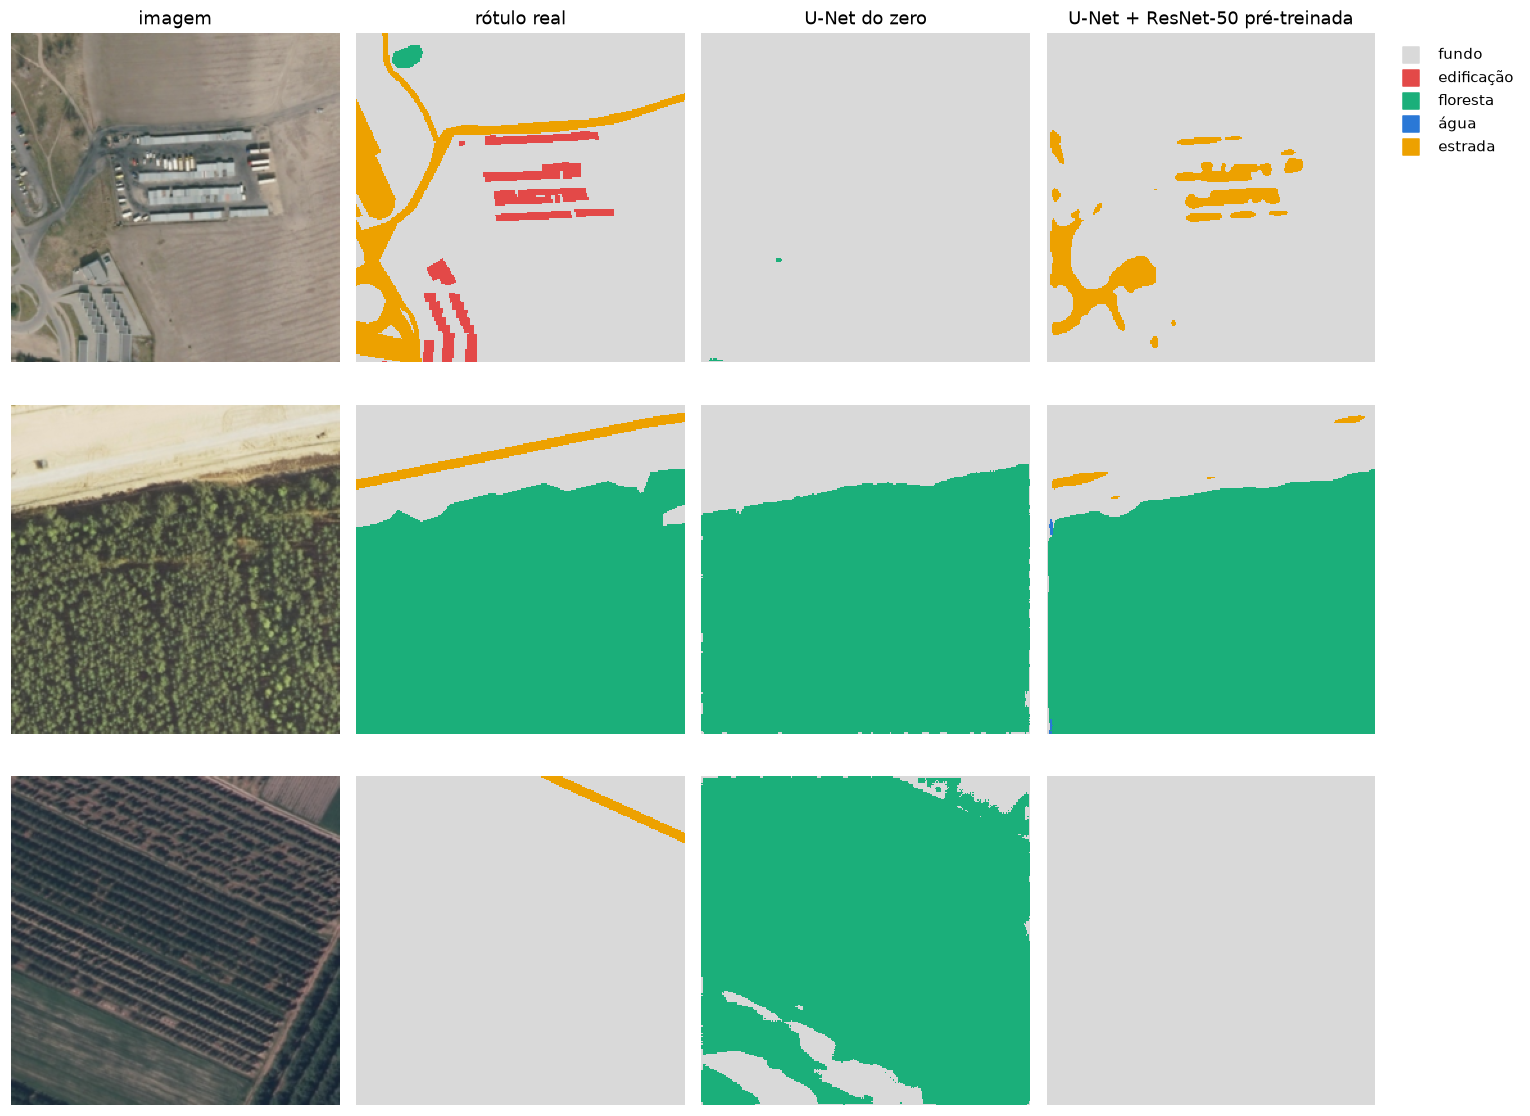

In [36]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10.5))
for linha, idx in enumerate([1, 6, 12]):
    paineis = [(X_te[idx].permute(1, 2, 0), "imagem"), (Y_te[idx], "rótulo real")] + \
              [(predicoes[nome][idx], nome) for nome in modelos_seg]
    for ax, (mapa, titulo) in zip(axes[linha], paineis):
        if titulo == "imagem":
            ax.imshow(mapa)
        else:
            ax.imshow(mapa, cmap=cmap_lc, vmin=0, vmax=4, interpolation="nearest")
        ax.axis("off")
        if linha == 0:
            ax.set_title(titulo)
for nome, cor in zip(NOMES_LC, CORES_LC):
    axes[0, 3].scatter([], [], marker="s", s=120, color=cor, label=nome)
axes[0, 3].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Leitura:**

- A **U-Net do zero**, com só 70 imagens, aprende o básico: separa **floresta** de **fundo**, mas praticamente não
  encontra água nem estradas (mIoU por volta de 0,25). Às vezes confunde texturas: na última linha, um pomar vira floresta.
- Trocando o encoder pela **ResNet-50 pré-treinada**, **sem treinar o encoder**, o mIoU **dobra** (por volta de 0,5):
  floresta e água ficam bem mapeadas, e as estradas começam a aparecer. A perda de treino também cai mais rápido.
- O que mudou não foi a quantidade de dados nem o decoder, e sim o **ponto de partida**: o encoder já sabia extrair bordas
  e texturas aprendidas em 1,2 milhão de fotos.
- As **edificações** (~1% dos pixels) ficam de fora nos dois modelos: em 256 × 256 as casas viram poucos pixels, e a perda
  é dominada pelo fundo. Para melhorar: descongelar o encoder (*fine-tuning*), usar 512 × 512, mais épocas e ponderar a
  perda pelas classes raras (exercícios).

# Parte 5 — Um primeiro olhar em *embeddings*

Todas as arquiteturas desta aula fazem a mesma coisa por dentro: transformam a entrada em **vetores de números em um
espaço de muitas dimensões**. Os mapas do encoder da U-Net, o vetor de 2.048 números que a ResNet-50 produz antes da
camada de classificação, os tokens de um Transformer: tudo isso são **representações** da entrada.

Quando essa representação é um vetor que **resume** um objeto (uma imagem, um pedaço de imagem, uma palavra, um texto),
chamamos de ***embedding***. A propriedade que torna embeddings tão úteis:

> objetos **parecidos** ficam **próximos** no espaço de embeddings.

É como um mapa, só que com 2.048 eixos em vez de 2. Ninguém escolhe o significado de cada eixo: eles surgem do treino.

## 5.1 O embedding de uma imagem

Na ResNet-50, o embedding é a saída do *global average pooling* (seção 2.6): os 2.048 mapas da última camada
convolucional, cada um resumido pela sua média. É a entrada da última camada linear, a que escolhe entre as 1.000
classes do ImageNet.

In [37]:
resnet50 = resnet50.to(DEVICE).eval()

@torch.no_grad()
def embedding(lote_imagens):
    """lote_imagens: (N, 3, 224, 224) já normalizado → (N, 2048)."""
    mapas = resnet50.forward_features(lote_imagens.to(DEVICE))    # (N, 2048, 7, 7)
    return resnet50.forward_head(mapas, pre_logits=True).cpu()     # global average pooling → (N, 2048)

x = transformacao(Image.fromarray(data.chelsea())).unsqueeze(0)
with torch.no_grad():
    print(f"mapas da última camada convolucional: {tuple(resnet50.forward_features(x.to(DEVICE)).shape)}")
e = embedding(x)
print(f"embedding do gato: {tuple(e.shape)}")
print(f"primeiros 8 dos 2.048 números: {e[0, :8].numpy().round(2)}")
print(f"{(e == 0).float().mean():.0%} dos números são zero: a última camada passa por uma ReLU, e cada imagem ativa só parte dos 2.048 detectores")

mapas da última camada convolucional: (1, 2048, 7, 7)
embedding do gato: (1, 2048)
primeiros 8 dos 2.048 números: [0.   0.   0.   0.   0.   0.   0.   0.12]
65% dos números são zero: a última camada passa por uma ReLU, e cada imagem ativa só parte dos 2.048 detectores


## 5.2 Um mapa das imagens aéreas no espaço de embeddings

Cortamos as 100 imagens do LandCover.ai em pedaços de 128 × 128 pixels (16 por imagem) e calculamos o embedding de
cada pedaço com a ResNet-50 pré-treinada, **sem nenhum treino adicional**. Cada pedaço recebe como "rótulo" a classe
mais frequente nos seus pixels; ficamos só com os pedaços em que essa classe cobre pelo menos 60% da área. Edificações e estradas são estreitas demais
para dominar um pedaço inteiro, então nesta seção sobram três classes: fundo, floresta e água.

In [38]:
TILE = 128
todos_ids = ids["train"] + ids["val"] + ids["test"]
tiles, classes_tile, origem = [], [], []
for img_id in todos_ids:
    img = torch.tensor(io.imread(f"{PASTA_LC}/output/{img_id}.jpg")).permute(2, 0, 1).float() / 255
    mascara = torch.tensor(io.imread(f"{PASTA_LC}/output/{img_id}_m.png")[..., 0]).long()
    for i in range(0, 512, TILE):
        for j in range(0, 512, TILE):
            contagem = torch.bincount(mascara[i:i + TILE, j:j + TILE].flatten(), minlength=5)
            classe = int(contagem.argmax())
            if contagem[classe] / contagem.sum() >= 0.6:
                tiles.append(img[:, i:i + TILE, j:j + TILE])
                classes_tile.append(classe)
                split = "train" if img_id in ids["train"] else "teste"
                origem.append((img_id, split))
tiles = torch.stack(tiles)
classes_tile = np.array(classes_tile)
print(f"{len(tiles)} pedaços de {TILE} × {TILE}:", {NOMES_LC[c]: int((classes_tile == c).sum()) for c in range(5)})

# edificações e estradas quase nunca ocupam 60% de um pedaço: ficamos só com as classes com pelo menos 20 pedaços
fica = np.isin(classes_tile, [c for c in range(5) if (classes_tile == c).sum() >= 20])
tiles, classes_tile = tiles[torch.tensor(fica)], classes_tile[fica]
origem = [o for o, f in zip(origem, fica) if f]
split_tile = np.array([s for _, s in origem])
print(f"ficamos com {len(tiles)} pedaços:", {NOMES_LC[c]: int((classes_tile == c).sum()) for c in np.unique(classes_tile)})

inicio = time.time()
entrada = normaliza(F.interpolate(tiles, size=224, mode="bilinear", antialias=True))   # a ResNet-50 espera 224 × 224
embeddings = torch.cat([embedding(entrada[k:k + 64]) for k in range(0, len(entrada), 64)])
print(f"embeddings: {tuple(embeddings.shape)} ({time.time() - inicio:.0f} s)")

1477 pedaços de 128 × 128: {'fundo': 964, 'edificação': 2, 'floresta': 394, 'água': 116, 'estrada': 1}
ficamos com 1474 pedaços: {'fundo': 964, 'floresta': 394, 'água': 116}


embeddings: (1474, 2048) (11 s)


Não dá para desenhar 2.048 dimensões. O **t-SNE** é um método que projeta pontos de muitas dimensões em 2D
**preservando quem é vizinho de quem**: pontos próximos no espaço original continuam próximos no desenho (as
distâncias grandes não têm significado).

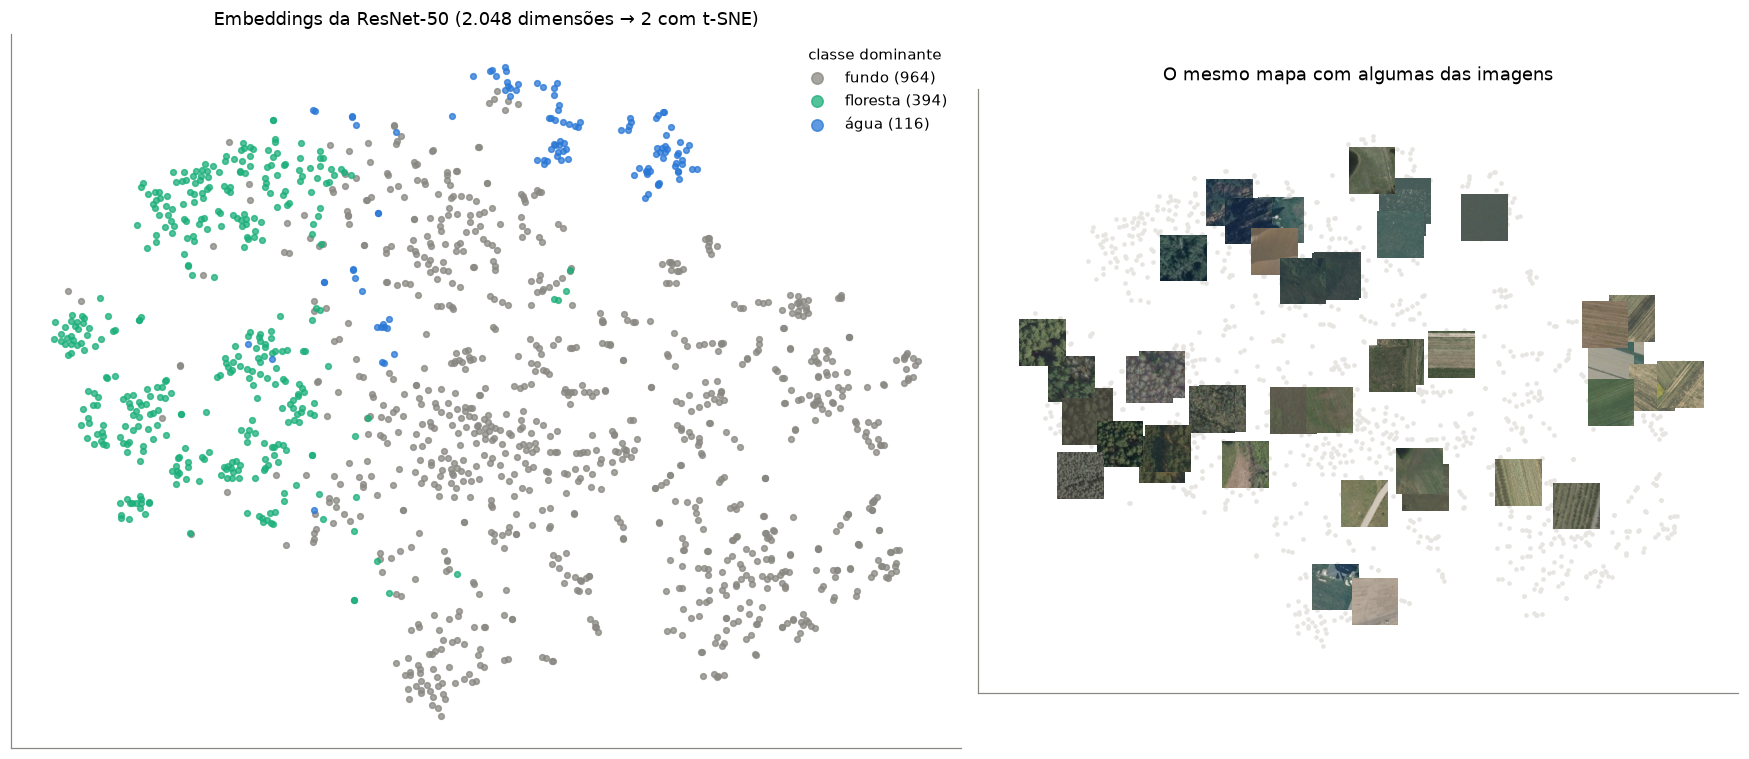

In [39]:
from sklearn.manifold import TSNE

xy = TSNE(n_components=2, perplexity=30, random_state=0, init="pca").fit_transform(embeddings.numpy())
cores_pontos = ["#898781"] + CORES_LC[1:]          # o "fundo" em cinza mais escuro, para aparecer no branco

fig, axes = plt.subplots(1, 2, figsize=(16, 7), width_ratios=[1.25, 1])
for c in np.unique(classes_tile):
    m = classes_tile == c
    axes[0].scatter(xy[m, 0], xy[m, 1], s=14, color=cores_pontos[c], alpha=0.75, label=f"{NOMES_LC[c]} ({m.sum()})")
axes[0].set(title="Embeddings da ResNet-50 (2.048 dimensões → 2 com t-SNE)", xticks=[], yticks=[])
axes[0].legend(frameon=False, markerscale=2, title="classe dominante")

# algumas miniaturas sobre o mapa, para ver o que há em cada região
gerador = np.random.default_rng(0)
meio = 0.035 * (xy.max() - xy.min())                  # metade do lado de cada miniatura
axes[1].scatter(xy[:, 0], xy[:, 1], s=4, color="#e6e5e1")
for k in gerador.choice(len(tiles), 45, replace=False):
    caixa = [xy[k, 0] - meio, xy[k, 0] + meio, xy[k, 1] - meio, xy[k, 1] + meio]
    axes[1].imshow(tiles[k].permute(1, 2, 0), extent=caixa, zorder=3)
axes[1].set(title="O mesmo mapa com algumas das imagens", xticks=[], yticks=[],
            xlim=(xy[:, 0].min() - 2 * meio, xy[:, 0].max() + 2 * meio), ylim=(xy[:, 1].min() - 2 * meio, xy[:, 1].max() + 2 * meio))
for ax in axes:
    ax.grid(False)
plt.tight_layout()
plt.show()

**Leitura:** a ResNet-50 nunca viu uma imagem aérea nem um rótulo de uso do solo, e mesmo assim os pedaços de
**floresta** se agrupam em uma região e os de **água** em outra (na verdade em dois grupos: água escura e água clara,
esverdeada). O **fundo** (campos, solo exposto, áreas urbanas) se espalha pelo resto, em subgrupos por textura:
plantações em linhas, solo nu, gramado. As características que a rede aprendeu com fotos comuns já **organizam** as
imagens aéreas por semelhança.

## 5.3 Busca por similaridade

Se imagens parecidas têm embeddings próximos, dá para **buscar imagens parecidas** com uma conta simples. A medida
mais usada é a **similaridade de cosseno**: o cosseno do ângulo entre dois vetores (1 = mesma direção, 0 = sem relação).

$$\text{sim}(a, b) = \frac{a \cdot b}{\|a\|\,\|b\|}$$

Para cada imagem de consulta, buscamos as 5 mais parecidas entre os pedaços de **outras** fotos (para não valer pedaços
vizinhos da mesma foto).

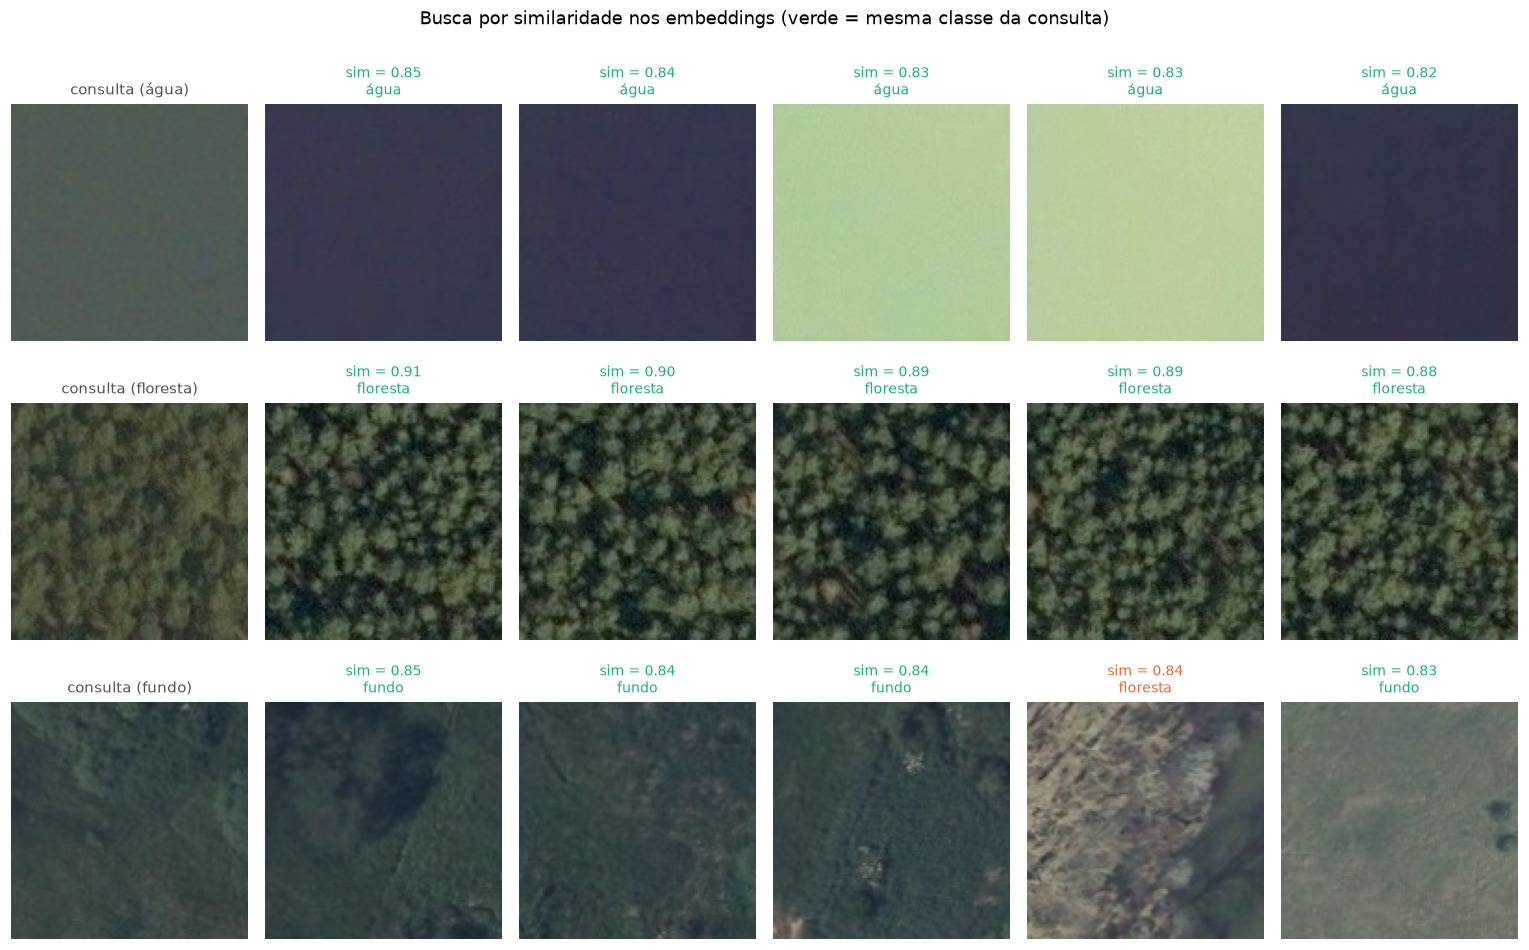

In [40]:
emb_norm = F.normalize(embeddings, dim=1)                 # vetores de comprimento 1: o produto escalar vira o cosseno
similaridade = emb_norm @ emb_norm.T                      # (N, N): a similaridade de cada par de pedaços
foto = np.array([i for i, _ in origem])

consultas = [int(np.flatnonzero(classes_tile == c)[3]) for c in [3, 2, 0]]      # água, floresta, fundo
fig, axes = plt.subplots(len(consultas), 6, figsize=(14, 2.95 * len(consultas)))
for linha, q in enumerate(consultas):
    s = similaridade[q].clone()
    s[torch.tensor(foto == foto[q])] = -1                 # ignora pedaços da mesma foto
    vizinhos = s.topk(5).indices
    axes[linha, 0].imshow(tiles[q].permute(1, 2, 0))
    axes[linha, 0].set_title(f"consulta ({NOMES_LC[classes_tile[q]]})", color=TINTA, fontsize=10)
    for k, v in enumerate(vizinhos):
        axes[linha, k + 1].imshow(tiles[v].permute(1, 2, 0))
        axes[linha, k + 1].set_title(f"sim = {s[v]:.2f}\n{NOMES_LC[classes_tile[v]]}", fontsize=9,
                                     color=VERDE if classes_tile[v] == classes_tile[q] else LARANJA)
    for ax in axes[linha]:
        ax.axis("off")
plt.suptitle("Busca por similaridade nos embeddings (verde = mesma classe da consulta)", y=1.0)
plt.tight_layout()
plt.show()

## 5.4 Embeddings como features prontas

Um embedding também é uma ótima **tabela de features** para os métodos de Machine Learning clássico. Com um simples
**k-vizinhos mais próximos** (k-NN) sobre os embeddings, sem treinar a rede, classificamos a classe dominante dos pedaços
das fotos de **teste** usando só os pedaços das fotos de **treino**:

In [41]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score

treino_t, teste_t = split_tile == "train", split_tile == "teste"
knn = KNeighborsClassifier(n_neighbors=5, metric="cosine").fit(embeddings[treino_t].numpy(), classes_tile[treino_t])
pred_knn = knn.predict(embeddings[teste_t].numpy())
maioria = np.bincount(classes_tile[treino_t]).argmax()

print(f"pedaços de treino: {treino_t.sum()}, de teste: {teste_t.sum()}")
print(f"k-NN nos embeddings:  acurácia = {accuracy_score(classes_tile[teste_t], pred_knn):.1%}   "
      f"acurácia balanceada = {balanced_accuracy_score(classes_tile[teste_t], pred_knn):.1%}")
print(f"chutar sempre '{NOMES_LC[maioria]}': acurácia = {(classes_tile[teste_t] == maioria).mean():.1%}")

pedaços de treino: 1023, de teste: 451
k-NN nos embeddings:  acurácia = 87.1%   acurácia balanceada = 78.5%
chutar sempre 'fundo': acurácia = 61.9%


**Leitura:** sem treinar a rede e sem nenhum ajuste, um k-NN sobre os embeddings acerta muito mais do que chutar sempre a
classe mais comum. A **acurácia balanceada** (a média do acerto em cada classe) mostra que ele também acerta as classes
menores, não só o fundo. É por isso que embeddings de modelos pré-treinados são tão usados: transformam imagens em
tabelas de features prontas para os métodos clássicos das aulas de Machine Learning.

### Embeddings em observação da Terra

A mesma ideia está mudando o sensoriamento remoto: em vez de baixar e processar imagens brutas, já é possível usar
**embeddings prontos**, calculados por modelos de fundação. Exemplos:

- o **Satellite Embedding** do Google (modelo AlphaEarth Foundations, 2025), disponível no Earth Engine: um vetor de 64
  números por pixel de 10 m, para cada ano, que resume as observações de vários satélites;
- os modelos **Clay** e **Prithvi**, que geram embeddings de recortes de imagens de satélite, disponíveis no Hugging Face.

Com embeddings, tarefas como "encontre áreas parecidas com esta", agrupar regiões ou treinar um classificador com
poucos exemplos ficam rápidas e baratas. **Na próxima aula** veremos o mecanismo de **atenção** e os Transformers, que
produzem um embedding para **cada** pedaço da imagem (ou cada palavra de um texto).

# Resumo

| Arquitetura | Ano | Era | Tipo de treino | Ideia-chave | Ponto fraco |
|---|---|---|---|---|---|
| CNN / LeNet-5 | 1998 | antiga | supervisionado | filtros aprendidos, pesos compartilhados | contexto local |
| AlexNet | 2012 | antiga | supervisionado (ImageNet) | profundidade + GPU + ReLU | pesada, ad hoc |
| VGG | 2014 | antiga | supervisionado (ImageNet) | empilhar convoluções 3 × 3 | 138 M parâmetros, para de melhorar com mais camadas |
| ResNet | 2015 | clássica, muito usada | supervisionado (ImageNet) | **skip connections** (soma) | ainda é local |
| U-Net | 2015 | clássica, muito usada | supervisionado (máscaras) | encoder-decoder + skips longas (concatenação) | precisa de máscaras rotuladas |

- **Convolução**: um filtro pequeno, com os mesmos pesos em toda a imagem.
- **CNN**: blocos de convolução e pooling (o que enxerga) + camadas densas ou GAP (o que decide).
- **ResNet**: a soma `F(x) + x` permite redes com dezenas ou centenas de camadas.
- **Hugging Face**: modelos e datasets pré-treinados prontos para usar; transferência de aprendizado.
- **U-Net**: segmentação pixel a pixel; com um encoder pré-treinado, funciona com poucas imagens rotuladas.
- **Embeddings**: as redes guardam o que aprenderam em vetores; imagens parecidas ficam próximas.

### Exercícios

1. Na seção 1.3, crie um kernel 3 × 3 que detecte bordas **diagonais**. Teste na foto.
2. No experimento da seção 2.4, aumente para 40 blocos (82 camadas). A rede residual ainda treina? E a comum?
3. Na `UNet` da seção 4.1, remova as skip connections (passe um tensor de zeros no lugar de `skip`). O que acontece com
   as bordas das classes nas previsões?
4. Na U-Net com ResNet-50, **descongele** o último estágio do encoder e treine de novo (*fine-tuning*). O mIoU melhora?
5. Use `F.cross_entropy(..., weight=pesos)` com pesos maiores para edificação e estrada. O IoU dessas classes melhora?
6. Na seção 5.4, troque os embeddings da ResNet-50 pelos **pixels brutos** dos pedaços (`tiles.flatten(1)`). O k-NN fica
   melhor ou pior? O que isso diz sobre os embeddings?